# Previsão da inflação — pesquisa em Python


## 1. Pacotes



In [2]:
from pathlib import Path
from datetime import datetime, timezone
from functools import reduce
from getpass import getpass
import os
import numpy as np
import pandas as pd
import plotly.express as px
import sidrapy
from bcb import sgs, Expectativas
import ipeadatapy as ipea
from fredapi import Fred
import statsmodels.api as sm
from statsmodels.tsa.filters.hp_filter import hpfilter
import os
from getpass import getpass


pd.set_option('display.max_columns', 50)

## 2. Configurações

- Foi utilizado dezembro/2002 como início da base. 
- As coletas serão feitas pelos pacotes. 
- Cada execução guarda as tabelas em uma pasta própria

In [4]:
PASTA_PROJETO = Path.cwd().resolve()
if not (PASTA_PROJETO / 'app.py').exists() and (PASTA_PROJETO / 'ipca_lab').is_dir():
    PASTA_PROJETO = PASTA_PROJETO / 'ipca_lab'
if not (PASTA_PROJETO / 'app.py').exists():
    raise RuntimeError('Abra o notebook a partir da pasta ipca_lab.')

INIT_DATE = '2002-12-01'
END_DATE = '2026-08-31'
assert pd.Timestamp(INIT_DATE) <= pd.Timestamp(END_DATE)
EXECUCAO = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
PASTA_DADOS = PASTA_PROJETO / 'dados' / EXECUCAO
PASTA_DADOS.mkdir(parents=True, exist_ok=False)
print('Pasta desta execução:', PASTA_DADOS)

Pasta desta execução: C:\Users\Usuário\Desktop\projeto_ml\ipca_lab\dados\20261005T182429799981Z


## 3. Coleta dos dados

### 3.1. PME e PNAD


In [6]:
arquivo_pme = PASTA_PROJETO / 'pme.csv'

pme_raw = pd.read_csv(arquivo_pme, sep=';', decimal=',')
meses_pt = {'jan':'01', 'fev':'02', 'mar':'03', 'abr':'04', 'mai':'05', 'jun':'06',
            'jul':'07', 'ago':'08', 'set':'09', 'out':'10', 'nov':'11', 'dez':'12'}

partes = pme_raw.iloc[:, 0].astype(str).str.strip().str.lower().str.split('/', expand=True)

mes = partes[0].map(meses_pt)
ano = pd.to_numeric(partes[1], errors='raise')
ano = ano.where(ano >= 100, ano + 2000)
pme = pd.DataFrame({
    'date': pd.to_datetime(ano.astype(str) + '-' + mes + '-01', errors='raise'),
    'pme': pd.to_numeric(pme_raw['pme'], errors='raise'),
})
if pme['date'].isna().any() or pme['date'].duplicated().any():
    raise ValueError('Conferir datas da PME.')

pnad = sgs.get({'pnad': 24369}, start='2002-03-01', end=END_DATE)
pnad = pnad.rename_axis('date').reset_index()
pnad['date'] = pd.to_datetime(pnad['date']).dt.to_period('M').dt.to_timestamp()
pnad.to_csv(PASTA_DADOS / 'pnad.csv', index=False)

mercado_trabalho = pme.merge(pnad, on='date', how='outer', validate='one_to_one').sort_values('date')


#### Regressão e PNAD ampliada

Estimamos PNAD ~ PME nos meses em que ambas existem. Somente o período anterior à PNAD será reconstruído. Lacunas posteriores não são preenchidas pela regressão.

Essa reconstrução usa uma relação estimada posteriormente ao início da PME: é uma série histórica sintética, não informação conhecida em tempo real. Para avaliar previsões históricas, não usar essa extensão sem controlar a disponibilidade da regressão em cada origem.

In [1]:
sobreposicao = mercado_trabalho.dropna(subset=['pme', 'pnad'])
if len(sobreposicao) < 3 or sobreposicao['pme'].nunique() < 2:
    raise ValueError('Sobreposição PME/PNAD insuficiente para regressão.')
reg = sm.OLS(sobreposicao['pnad'], sm.add_constant(sobreposicao[['pme']], has_constant='add')).fit()
#print(reg.summary())

primeira_pnad = mercado_trabalho.loc[mercado_trabalho['pnad'].notna(), 'date'].min()
reconstruir = (mercado_trabalho['date'] < primeira_pnad) & mercado_trabalho['pme'].notna()
mercado_trabalho['desemprego'] = mercado_trabalho['pnad']
mercado_trabalho.loc[reconstruir, 'desemprego'] = reg.predict(
    sm.add_constant(mercado_trabalho.loc[reconstruir, ['pme']], has_constant='add')
)

mercado_trabalho['desemprego'] = mercado_trabalho['desemprego'].round(1)
desemprego = mercado_trabalho[['date', 'desemprego']].copy()
desemprego.head()

NameError: name 'mercado_trabalho' is not defined

### 3.2. IBGE — SIDRA

 A função abaixo só organiza a resposta do `sidrapy`: o primeiro registro traz os nomes das colunas. Símbolos de ausência permanecem ausentes; valores numéricos mantêm a unidade de cada tabela.

[Documentação do sidrapy](https://sidrapy.readthedocs.io/pt-br/latest/modules/table.html)

In [6]:
ipca = sidrapy.get_table(
    table_code='1737',
    territorial_level='1',
    ibge_territorial_code='all',
    variable='63',
    period='all',
    header='y'
)
ipca.head()
ipca.columns.tolist()
ipca.columns = ipca.iloc[0].tolist()
ipca = ipca.iloc[1:].reset_index(drop=True)


ipca_tratado = ipca[['Mês (Código)', 'Valor']].copy()

ipca_tratado = ipca_tratado.rename(columns={'Mês (Código)': 'date', 'Valor': 'ipca'})
ipca_tratado['date'] = pd.to_datetime(ipca_tratado['date'].astype(str) + '01', format='%Y%m%d', errors='raise')



In [7]:
ipca_tratado['ipca'].value_counts()

ipca_tratado['ipca'] = ipca_tratado['ipca'].replace(
    {'...': np.nan, '..': np.nan, 'X': np.nan}
)

ipca_tratado['ipca'] = pd.to_numeric(
    ipca_tratado['ipca'],
    errors='raise'
)

ipca_tratado = ipca_tratado.sort_values('date').reset_index(drop=True)



ipca_tratado.info()


display(ipca_tratado.tail())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 561 entries, 0 to 560
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    561 non-null    datetime64[ns]
 1   ipca    560 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 8.9 KB


,date,ipca
556,2026-04-01,0.67
557,2026-05-01,0.58
558,2026-06-01,0.16
559,2026-07-01,0.07
560,2026-08-01,-0.32


In [8]:
def organizar_sidra(resposta):
    tabela = resposta.iloc[1:].copy()
    tabela.columns = resposta.iloc[0].tolist()
    tabela['date'] = pd.to_datetime(tabela['Mês (Código)'].astype(str), format='%Y%m')
    valores = tabela['Valor'].replace({'...': np.nan, '..': np.nan, '-': np.nan, 'X': np.nan})
    tabela['Valor'] = pd.to_numeric(valores, errors='raise')
    return tabela.loc[tabela['date'].between(INIT_DATE, END_DATE)].copy()

In [11]:
ipca_raw = sidrapy.get_table(table_code='1737', territorial_level='1', ibge_territorial_code='all',
                             variable='63', period='all', header='y')

ipca = organizar_sidra(ipca_raw)[['date', 'Valor']].rename(columns={'Valor': 'ipca'})

ipca_15_raw = sidrapy.get_table(table_code='3065', territorial_level='1', ibge_territorial_code='all',
                                variable='355', period='all', header='y')

ipca_15 = organizar_sidra(ipca_15_raw)[['date', 'Valor']].rename(columns={'Valor': 'ipca_15'})

display(ipca_15.tail(), ipca.tail())

,date,ipca_15
312,2026-04-01,0.89
313,2026-05-01,0.62
314,2026-06-01,0.41
315,2026-07-01,0.06
316,2026-08-01,-0.40


,date,ipca
557,2026-04-01,0.67
558,2026-05-01,0.58
559,2026-06-01,0.16
560,2026-07-01,0.07
561,2026-08-01,-0.32


In [12]:
pim_raw = sidrapy.get_table(table_code='8888', territorial_level='1', ibge_territorial_code='all',
                            variable='11601', classifications={'544': '129314'}, period='all', header='y')
pim_pf = organizar_sidra(pim_raw)[['date', 'Valor']].rename(columns={'Valor': 'pim_pf'})

consumo_raw = sidrapy.get_table(table_code='8887', territorial_level='1', ibge_territorial_code='all',
                                variable='11601', classifications={'543': '129300'}, period='all', header='y')
pim_pf_consumo = organizar_sidra(consumo_raw)[['date', 'Valor']].rename(columns={'Valor': 'pim_pf_bens_consumo'})



In [13]:
pmc_raw = sidrapy.get_table(table_code='8880', territorial_level='1', ibge_territorial_code='all',
                            variable='11708', classifications={'11046': 'all'}, period='all', header='y')
pmc_longa = organizar_sidra(pmc_raw)

pmc = pmc_longa.pivot(index='date', columns='Tipos de índice', values='Valor').rename(columns={
    'Índice de receita nominal de vendas no comércio varejista': 'receita_nominal',
    'Índice de volume de vendas no comércio varejista': 'volume',
}).reset_index()

if not {'receita_nominal', 'volume'} <= set(pmc.columns):
    raise ValueError(f'Conferir categorias da PMC: {list(pmc.columns)}')

pmc = pmc[['date', 'receita_nominal', 'volume']]

base_ibge = reduce(lambda a, b: a.merge(b, on='date', how='left', validate='one_to_one'),
                   [ipca, ipca_15, pim_pf, pim_pf_consumo, pmc]).sort_values('date')
df_ibge = base_ibge.copy()

for nome, bruto in {'ipca': ipca_raw, 'ipca_15': ipca_15_raw, 'pim': pim_raw,
                    'consumo': consumo_raw, 'pmc': pmc_raw}.items():
    bruto.to_csv(PASTA_DADOS / f'sidra_{nome}_raw.csv', index=False)
df_ibge.tail(10)

,date,ipca,ipca_15,pim_pf,pim_pf_bens_consumo,receita_nominal,volume
275,2025-11-01,0.18,0.20,-0.2,0.4,0.9,1.1
276,2025-12-01,0.33,0.25,-2.0,-1.5,-0.4,-0.7
277,2026-01-01,0.33,0.20,2.1,1.6,0.5,0.5
278,2026-02-01,0.70,0.84,0.9,0.6,0.5,0.8
279,2026-03-01,0.88,0.44,0.1,0.4,1.2,0.5
280,2026-04-01,0.67,0.89,1.1,-0.9,1.1,-1.1
281,2026-05-01,0.58,0.62,-1.0,-1.0,0.1,0.2
282,2026-06-01,0.16,0.41,-1.6,-3.1,0.7,0.3
283,2026-07-01,0.07,0.06,0.1,0.3,-0.6,-0.8
284,2026-08-01,-0.32,-0.40,-0.6,-1.5,NaN,NaN


### 3.3. Banco Central

`rbcb::get_series()` passa a ser `sgs.get()` do pacote `python-bcb`. O dicionário abaixo contém os mesmos 17 códigos do seu bloco Bacen. O IPCA já veio do SIDRA.

[Documentação do SGS em Python](https://wilsonfreitas.github.io/python-bcb/sgs.html)

In [9]:
teste = 3698

teste = sgs.get(teste, start=INIT_DATE, end=END_DATE)

teste = teste.rename_axis('date').reset_index()
teste = teste.rename(columns={teste.columns[1]: 'cambio'})
teste['date'] = pd.to_datetime(teste['date']).dt.to_period('M').dt.to_timestamp()

teste.tail()

,date,cambio
280,2026-04-01,5.0331
281,2026-05-01,4.9837
282,2026-06-01,5.1276
283,2026-07-01,5.1139
284,2026-08-01,5.1532


In [ ]:
series_bcb = {
    'cambio': 3698, 
    'pib_mensal': 4380, 
    'igp_m': 189, 
    'igp_di': 190,
    'm1': 27788, 
    'm2': 27810, 
    'm3': 27813, 
    'm4': 27815,
    'estoque_caged': 28763, 
    'saldo_bc': 22707, 'vendas_auto': 7384,
    'divida_liquida_spc': 4513, 'selic': 4189, 'idp': 22885,
    'cambio_real': 11752, 'tjlp': 256, 'cdi': 4391,
}
df_bcb = sgs.get(series_bcb, start=INIT_DATE, end=END_DATE)

df_bcb = df_bcb.rename_axis('date').reset_index()
df_bcb['date'] = pd.to_datetime(df_bcb['date']).dt.to_period('M').dt.to_timestamp()
if df_bcb['date'].duplicated().any():
    raise ValueError('Conferir frequência das séries BCB antes de agregar.')
df_bcb.to_csv(PASTA_DADOS / 'bcb.csv', index=False)
df_bcb.tail()

ValueError: Expected object or value

### 3.4. Focus

A API mensal é `ExpectativaMercadoMensais`. Consultamos por mês para limitar cada resposta, com `baseCalculo=0`. Depois aplicamos a regra do R: última data disponível até o dia 15 do mês e horizontes de 1 a 12 meses. Preservamos também a data da pesquisa e o mês-alvo; eles serão necessários para avaliar a previsão corretamente.

[Documentação de expectativas](https://wilsonfreitas.github.io/python-bcb/expectativas.html)

In [16]:
expectativas = Expectativas()
ep = expectativas.get_endpoint('ExpectativaMercadoMensais')
partes_focus = []

for mes in pd.period_range(INIT_DATE, END_DATE, freq='M'):
    inicio = max(mes.start_time.date(), pd.Timestamp(INIT_DATE).date())
    fim = min(mes.end_time.date(), pd.Timestamp(END_DATE).date())
    parte = (ep.query()
             .filter(ep.Indicador == 'IPCA', ep.baseCalculo == 0)
             .filter(ep.Data >= inicio, ep.Data <= fim)
             .limit(10000).collect())
    if len(parte) >= 10000:
        raise ValueError(f'Resposta Focus atingiu o limite em {mes}; subdivida a consulta.')
    if not parte.empty:
        partes_focus.append(parte)
if not partes_focus:
    raise ValueError('Focus não retornou dados.')
focus_raw = pd.concat(partes_focus, ignore_index=True)
focus_raw.to_csv(PASTA_DADOS / 'focus_raw.csv', index=False)
focus_raw.head()

KeyboardInterrupt: 

In [37]:
focus = focus_raw.copy()
focus['Data'] = pd.to_datetime(focus['Data'])
focus['data_alvo'] = pd.to_datetime(focus['DataReferencia'], format='%m/%Y')
focus['date'] = focus['Data'].dt.to_period('M').dt.to_timestamp()
focus['horizon'] = ((focus['data_alvo'].dt.year - focus['Data'].dt.year) * 12
                    + focus['data_alvo'].dt.month - focus['Data'].dt.month)
focus = focus.loc[(focus['baseCalculo'] == 0) & focus['horizon'].between(1, 12)
                  & (focus['Data'].dt.day <= 15)].copy()
ultima_data = focus.groupby('date')['Data'].transform('max')
focus_selecionado = focus.loc[focus['Data'].eq(ultima_data)].copy()
if focus_selecionado.duplicated(['date', 'horizon']).any():
    raise ValueError('Focus tem mais de uma mediana para a mesma origem e horizonte; investigar.')
df_focus = focus_selecionado.pivot(index='date', columns='horizon', values='Mediana')
df_focus = df_focus.reindex(columns=range(1, 13)).add_prefix('expectativa_ipca_h_').reset_index()
focus_selecionado.to_csv(PASTA_DADOS / 'focus_com_datas.csv', index=False)
df_focus.tail()

horizon,date,expectativa_ipca_h_1,expectativa_ipca_h_2,expectativa_ipca_h_3,expectativa_ipca_h_4,expectativa_ipca_h_5,expectativa_ipca_h_6,expectativa_ipca_h_7,expectativa_ipca_h_8,expectativa_ipca_h_9,expectativa_ipca_h_10,expectativa_ipca_h_11,expectativa_ipca_h_12
280,2026-04-01,0.3300,0.28,0.2356,0.1990,0.2992,0.25,0.2200,0.4158,0.3700,0.5550,0.330,0.3533
281,2026-05-01,0.3000,0.25,0.0886,0.3100,0.2400,0.24,0.4100,0.3849,0.5700,0.3317,0.370,0.2600
282,2026-06-01,0.3100,0.03,0.4300,0.2568,0.2735,0.44,0.4026,0.5900,0.3502,0.3900,0.290,0.2500
283,2026-07-01,-0.1000,0.49,0.3000,0.2700,0.4910,0.43,0.6054,0.3696,0.4000,0.3000,0.240,0.2400
284,2026-08-01,0.5088,0.33,0.3200,0.5200,0.4300,0.62,0.3900,0.4000,0.3000,0.2300,0.225,0.1584


### 3.5. Ipeadata

`ipeadatapy.timeseries()` consulta os mesmos códigos de `ipeadatar::ipeadata()`. A coluna de valores é identificada pelo prefixo `VALUE`, que contém a unidade no nome. A média mensal segue a regra do seu R, inclusive para séries diárias; antes do treinamento, vamos revisar se essa agregação atende a cada variável.

[Documentação do ipeadatapy](https://www.luanborelli.net/ipeadatapy/docs/usage/functions/timeseries.html)

In [38]:
series_ipea = {
    'ltn': 'ANBIMA12_TJTLN1212', 'ir': 'SRF12_IR12',
    'ibovespa': 'GM12_IBVSP12', 'consumo_energia': 'ELETRO12_CEET12',
    'brent_fob': 'EIA366_PBRENT366',
}
tabelas_ipea = []
for nome, codigo in series_ipea.items():
    bruto = ipea.timeseries(codigo)
    if bruto.empty:
        raise ValueError(f'Ipeadata sem dados: {codigo}')
    bruto.to_csv(PASTA_DADOS / f'ipea_{nome}_raw.csv')
    colunas_valor = [c for c in bruto.columns if str(c).startswith('VALUE')]
    if len(colunas_valor) != 1:
        raise ValueError(f'Conferir coluna de valores de {codigo}: {list(bruto.columns)}')
    datas = pd.to_datetime(bruto.index)
    valores = pd.to_numeric(bruto[colunas_valor[0]], errors='raise')
    tabela = pd.DataFrame({'date': datas, nome: valores.to_numpy()})
    tabela['date'] = tabela['date'].dt.to_period('M').dt.to_timestamp()
    tabela = tabela.groupby('date', as_index=False)[nome].mean()
    tabela = tabela.loc[tabela['date'].between(INIT_DATE, END_DATE)]
    tabelas_ipea.append(tabela)
df_ipea = reduce(lambda a, b: a.merge(b, on='date', how='outer', validate='one_to_one'), tabelas_ipea)
df_ipea = df_ipea.sort_values('date')
df_ipea.tail()

,date,ltn,ir,ibovespa,consumo_energia,brent_fob
280,2026-04-01,13.750595,90031.280576,-0.076816,49635.0,117.287500
281,2026-05-01,13.837600,94558.141644,-7.223011,48035.0,107.139474
282,2026-06-01,14.267174,86250.818796,-1.015030,46203.0,85.399091
283,2026-07-01,13.871530,90293.861740,3.473353,46841.0,83.758696
284,2026-08-01,13.692524,66153.128457,-0.325845,NaN,91.076000


### 3.7. FRED — PPI americano


[Documentação do fredapi](https://github.com/mortada/fredapi)

In [39]:
os.environ["FRED_API_KEY"] = getpass("Cole sua chave do FRED: ")
fred = Fred(api_key=os.environ["FRED_API_KEY"])

In [ ]:
chave_fred = os.environ.get('FRED_API_KEY') or getpass('Chave da API FRED: ')

if not chave_fred:
    raise ValueError('Informe a chave FRED para coletar o PPI.')
fred = Fred(api_key=chave_fred)
del chave_fred

ppi = fred.get_series('PPIACO', observation_start=INIT_DATE, observation_end=END_DATE)
ppi_usa = ppi.rename('ppi').rename_axis('date').reset_index()
ppi_usa['date'] = pd.to_datetime(ppi_usa['date']).dt.to_period('M').dt.to_timestamp()

if ppi_usa['date'].duplicated().any():
    raise ValueError('PPI tem meses duplicados.')
ppi_usa = ppi_usa.set_index('date').asfreq('MS').reset_index()
if (ppi_usa['ppi'].dropna() <= 0).any():
    raise ValueError('PPI precisa ser positivo para o logaritmo.')

ppi_usa['dlog_ppi'] = np.log(ppi_usa['ppi']).diff()
ppi_usa.to_csv(PASTA_DADOS / 'ppi_usa.csv', index=False)



## 4. Juntando as bases

Como no R, usamos o IPCA como referência das datas e fazemos junções à esquerda. Não há preenchimento automático de valores ausentes. `desemprego_estimado` identifica o trecho reconstruído.

Este é um painel exploratório por mês de referência. O Focus possui data própria de pesquisa; as outras fontes têm atrasos de divulgação distintos. Vamos tratar esses alinhamentos antes dos modelos.

In [7]:
bases = [df_ibge, df_bcb, df_focus, df_ipea, desemprego, ppi_usa]
for base in bases:
    if base['date'].duplicated().any():
        raise ValueError('Uma base contém datas duplicadas.')
df_ipca = reduce(lambda a, b: a.merge(b, on='date', how='left', validate='one_to_one'), bases)
df_ipca = df_ipca.sort_values('date').reset_index(drop=True)
print('Dimensões da base:', df_ipca.shape)
df_ipca.tail()

NameError: name 'df_ibge' is not defined

## 5. Análise

In [43]:
cobertura = pd.DataFrame({
    'observacoes': df_ipca.drop(columns='date').count(),
    'ausentes': df_ipca.drop(columns='date').isna().sum(),
})
display(cobertura)
display(df_ipca['ipca'].describe())
fig = px.line(df_ipca, x='date', y='ipca', title='IPCA mensal', color_discrete_sequence=['blue'],
              labels={'date': 'Mês de referência', 'ipca': 'Variação mensal (%)'})
fig.show()

,observacoes,ausentes
ipca,285,0
ipca_15,285,0
pim_pf,284,1
pim_pf_bens_consumo,284,1
receita_nominal,284,1
volume,284,1
cambio,285,0
pib_mensal,285,0
igp_m,285,0
igp_di,285,0


count    285.000000
mean       0.472105
std        0.364977
min       -0.680000
25%        0.250000
50%        0.440000
75%        0.640000
max        2.250000
Name: ipca, dtype: float64

## 6. Salvar 

Os arquivos abaixo não indicam que o tratamento para previsão já foi concluído. As séries originais, o Focus com suas datas e a identificação da PME estimada ficam preservados.

In [17]:
df_ipca.to_csv(PASTA_DADOS / 'df_ipca_consolidado.csv', index=False)
cobertura.to_csv(PASTA_DADOS / 'cobertura.csv')
desemprego.to_csv(PASTA_DADOS / 'desemprego_ampliado.csv', index=False)
print('Dados salvos em:', PASTA_DADOS)

NameError: name 'df_ipca' is not defined

## 6.1 Carregar a base 

In [18]:
arquivos = list(Path("dados").glob("*/df_ipca_consolidado.csv"))

if not arquivos:
    raise FileNotFoundError("Nenhuma base consolidada encontrada em dados.")

#
arquivo_base = max(arquivos, key=lambda arquivo: arquivo.stat().st_mtime)

df_ipca = pd.read_csv(
    arquivo_base,
    parse_dates=["date"]
).sort_values("date").reset_index(drop=True)

print("Base carregada:", arquivo_base)
display(df_ipca.tail())

Base carregada: dados\20261002T101255537146Z\df_ipca_consolidado.csv


,date,ipca,ipca_15,pim_pf,pim_pf_bens_consumo,receita_nominal,volume,cambio,pib_mensal,igp_m,igp_di,m1,m2,m3,m4,estoque_caged,saldo_bc,vendas_auto,divida_liquida_spc,selic,idp,cambio_real,tjlp,cdi,expectativa_ipca_h_1,expectativa_ipca_h_2,expectativa_ipca_h_3,expectativa_ipca_h_4,expectativa_ipca_h_5,expectativa_ipca_h_6,expectativa_ipca_h_7,expectativa_ipca_h_8,expectativa_ipca_h_9,expectativa_ipca_h_10,expectativa_ipca_h_11,expectativa_ipca_h_12,ltn,ir,ibovespa,consumo_energia,brent_fob,desemprego,ppi,dlog_ppi
280,2026-04-01,0.67,0.89,1.2,-0.9,1.1,-1.1,5.0331,1160675.4,2.73,2.41,633512842,7494978369,13654729675,15300067144,47804347,9826.2,187297.0,67.13,14.64,9684.8,117.85,9.13,1.09,0.3300,0.28,0.2356,0.1990,0.2992,0.25,0.2200,0.4158,0.3700,0.5550,0.330,0.3533,13.750595,90031.280576,-0.076816,49635.0,117.287500,5.8,282.722,0.023668
281,2026-05-01,0.58,0.62,-1.0,-1.0,0.1,0.2,4.9837,1131023.2,0.84,0.87,633738427,7606418069,13862071499,15575157068,47885995,6566.7,214281.0,67.89,14.40,8538.0,116.20,9.13,1.07,0.3000,0.25,0.0886,0.3100,0.2400,0.24,0.4100,0.3849,0.5700,0.3317,0.370,0.2600,13.837600,94558.141644,-7.223011,48035.0,107.139474,5.6,290.200,0.026106
282,2026-06-01,0.16,0.41,-1.6,-3.2,0.7,0.3,5.1276,1134029.1,-0.50,-0.79,646791922,7719911836,13995924329,15766528051,48022954,8071.6,212879.0,68.49,14.29,9145.8,118.62,9.13,1.12,0.3100,0.03,0.4300,0.2568,0.2735,0.44,0.4026,0.5900,0.3502,0.3900,0.290,0.2500,14.267174,86250.818796,-1.015030,46203.0,85.399091,5.4,286.023,-0.014498
283,2026-07-01,0.07,0.06,0.2,0.3,-0.6,-0.8,5.1139,1162537.4,-1.16,-0.86,643776049,7737540247,14060679608,15821140385,48078869,5650.2,212691.0,69.13,14.15,6968.3,NaN,9.14,1.22,-0.1000,0.49,0.3000,0.2700,0.4910,0.43,0.6054,0.3696,0.4000,0.3000,0.240,0.2400,13.871530,90293.861740,3.473353,46841.0,83.758696,5.3,285.181,-0.002948
284,2026-08-01,-0.32,-0.40,NaN,NaN,NaN,NaN,5.1532,1149930.8,-0.22,0.06,638623076,7791450165,14174654364,15961037581,48244696,6621.7,NaN,69.26,13.94,7396.1,NaN,9.14,1.09,0.5088,0.33,0.3200,0.5200,0.4300,0.62,0.3900,0.4000,0.3000,0.2300,0.225,0.1584,13.692524,66153.128457,-0.325845,NaN,91.076000,5.3,287.928,0.009586


## 7. Tratamento 



In [19]:
from pathlib import Path
import pandas as pd

if 'df_ipca' not in globals():
    pasta_etapa7 = Path.cwd()
    if (pasta_etapa7 / 'ipca_lab').is_dir():
        pasta_etapa7 = pasta_etapa7 / 'ipca_lab'
    df_ipca = pd.read_csv(
        pasta_etapa7 / 'dados/etapa7_20260929/df_ipca_consolidado.csv',
        parse_dates=['date']
    )

df_ipca = df_ipca.sort_values('date').reset_index(drop=True)
print('Número de meses:', df_ipca.shape[0])
print('Número de variáveis:', df_ipca.shape[1] - 1)
print('Período:', df_ipca['date'].min(), 'a', df_ipca['date'].max())

Número de meses: 285
Número de variáveis: 43
Período: 2002-12-01 00:00:00 a 2026-08-01 00:00:00


### 7.1. Tipos das colunas

In [20]:
df_ipca.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 285 entries, 0 to 284
Data columns (total 44 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date                   285 non-null    datetime64[ns]
 1   ipca                   285 non-null    float64       
 2   ipca_15                285 non-null    float64       
 3   pim_pf                 284 non-null    float64       
 4   pim_pf_bens_consumo    284 non-null    float64       
 5   receita_nominal        284 non-null    float64       
 6   volume                 284 non-null    float64       
 7   cambio                 285 non-null    float64       
 8   pib_mensal             285 non-null    float64       
 9   igp_m                  285 non-null    float64       
 10  igp_di                 285 non-null    float64       
 11  m1                     285 non-null    int64         
 12  m2                     285 non-null    int64         
 13  m3   

### 7.2. Datas duplicadas

In [9]:
datas_duplicadas = df_ipca[df_ipca['date'].duplicated(keep=False)]
print('Linhas com datas duplicadas:', len(datas_duplicadas))
if not datas_duplicadas.empty:
    print(datas_duplicadas.to_string(index=False))

Linhas com datas duplicadas: 0


## 8. Tratamento e modelos



In [21]:
from pathlib import Path
from itertools import combinations
import json
import hashlib
import warnings
import numpy as np
import pandas as pd
from IPython.display import display
from arch.unitroot import ADF, KPSS, PhillipsPerron
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, ParameterGrid
from sklearn.metrics import mean_absolute_error, mean_squared_error
from joblib.externals import cloudpickle

# ========= Configurações ========= #
RAIZ = Path.cwd()
if (RAIZ / 'ipca_lab').is_dir():
    RAIZ = RAIZ / 'ipca_lab'
ARQUIVO_BASE = RAIZ / 'dados/20260929T124334411176Z/df_ipca_consolidado.csv'
df_ipca = pd.read_csv(ARQUIVO_BASE, parse_dates=['date']).sort_values('date')
df_ipca = df_ipca.loc[df_ipca['date'] <= '2026-06-01'].reset_index(drop=True)
if df_ipca['date'].duplicated().any():
    raise ValueError('A base contém meses duplicados.')
calendario = pd.date_range(df_ipca['date'].min(), df_ipca['date'].max(), freq='MS')
assert list(df_ipca['date']) == list(calendario), 'Existem lacunas no calendário mensal.'
HORIZONTES = [1, 3, 6, 12]
DATAS_TESTE = pd.date_range('2024-07-01', '2026-06-01', freq='MS')
ALPHA = 0.05
MAX_D = 2
print('Base:', df_ipca.shape, '| Teste:', DATAS_TESTE.min(), 'até', DATAS_TESTE.max())


Base: (283, 42) | Teste: 2024-07-01 00:00:00 até 2026-06-01 00:00:00


### 8.1. Testes e número de diferenças


Cada teste é aplicado em nível e com tendência. KPSS não rejeita estacionariedade
quando p ≥ 5%; ADF/PP rejeitam raiz unitária quando p < 5%. Repetimos a primeira
diferença até no máximo duas vezes. A escolha é a moda dos seis resultados; empates
ficam com o menor d, como a ordenação dos valores no relatório R.

Usamos ADF com uma defasagem, KPSS com floor(3√n/13) e PP com a largura curta
floor(4(n/100)^0,25), explicitando as configurações. Séries constantes recebem d=0.
Falhas e séries insuficientes interrompem a execução, em vez de produzir um d arbitrário.
Quando um teste não atinge seu critério até d=2, isso fica registrado no relatório.


In [22]:
def numero_diferencas(serie, teste, tendencia, alpha=ALPHA, max_d=MAX_D):
    x = pd.to_numeric(serie, errors='raise').dropna().to_numpy(dtype=float)
    if len(x) < 36 or not np.isfinite(x).all():
        raise ValueError(f'Série insuficiente ou inválida: {serie.name}')
    for d in range(max_d + 1):
        if np.ptp(x) < 1e-10:
            return d, True
        if teste == 'adf':
            resultado = ADF(x, lags=1, trend=tendencia)
        elif teste == 'kpss':
            resultado = KPSS(x, lags=int(3 * np.sqrt(len(x)) / 13), trend=tendencia)
        else:
            resultado = PhillipsPerron(x, lags=int(4 * (len(x) / 100) ** .25), trend=tendencia)
        p = float(resultado.pvalue)
        if not np.isfinite(p):
            raise ValueError(f'Teste sem valor-p válido: {serie.name}/{teste}/{tendencia}')
        estacionaria = p >= alpha if teste == 'kpss' else p < alpha
        if estacionaria:
            return d, True
        if d < max_d:
            x = np.diff(x)
    return max_d, False


def report_ndiffs(base_treino):
    # Como na função R, remove linhas incompletas antes dos testes.
    valores = base_treino.drop(columns='date').dropna()
    linhas = []
    for variavel in valores:
        linha = {'variable': variavel}
        votos, limites = [], []
        for teste in ['kpss', 'adf', 'pp']:
            for nome, tendencia in [('level', 'c'), ('trend', 'ct')]:
                d, atingiu = numero_diferencas(valores[variavel], teste, tendencia)
                linha[f'{teste}_{nome}'] = d
                votos.append(d)
                if not atingiu:
                    limites.append(f'{teste}_{nome}')
        linha['ndiffs'] = int(pd.Series(votos).mode().min())
        linha['d_aplicado'] = 0 if variavel == 'ipca' else linha['ndiffs']
        linha['testes_no_limite'] = ', '.join(limites)
        linhas.append(linha)
    return pd.DataFrame(linhas)


### 8.2. Diferenciação, defasagens e dummies





In [23]:
def preparar_base(base, relatorio, h):
    df_ipca_diff = base.copy()
    for linha in relatorio.itertuples():
        for _ in range(linha.d_aplicado):
            df_ipca_diff[linha.variable] = df_ipca_diff[linha.variable].diff()

    defasagens = {}
    for variavel in df_ipca_diff.columns.drop('date'):
        for lag in [1, 4]:
            defasagens[f'{variavel}_lag{lag}'] = df_ipca_diff[variavel].shift(lag)
    df_ipca_lagged = pd.concat([df_ipca_diff, pd.DataFrame(defasagens)], axis=1)
    preencher = df_ipca_lagged.columns.difference(['date', 'ipca'])
    df_ipca_lagged[preencher] = df_ipca_lagged[preencher].ffill()
    # Faz drop_na antes da seleção, seguindo a ordem do R.
    df_ipca_lagged = df_ipca_lagged.dropna().copy()
    remover = [c for c in df_ipca_diff if c != 'date' and 'ipca' not in c and 'expectativa' not in c]
    df_ipca_lagged = df_ipca_lagged.drop(columns=remover)
    data_alvo = df_ipca_lagged['date'] + pd.DateOffset(months=h)
    for mes in range(1, 12):
        df_ipca_lagged[f'mes_{mes:02d}'] = (data_alvo.dt.month == mes).astype(int)
    return df_ipca_diff, df_ipca_lagged


def dividir_com_tratamento(indices_treino, indices_avaliacao, h):
    fim_treino = int(max(indices_treino))
    fim_avaliacao = int(max(indices_avaliacao))
    relatorio = report_ndiffs(df_ipca.iloc[:fim_treino + 1])
    diferencas, painel = preparar_base(df_ipca.iloc[:fim_avaliacao + 1], relatorio, h)
    # Alvos em escala original, sem preenchimento de IPCA ausente.
    painel['alvo'] = df_ipca['ipca'].shift(-h).reindex(painel.index)
    painel['data_alvo'] = painel['date'] + pd.DateOffset(months=h)
    treino = painel.loc[painel.index.intersection(indices_treino)].dropna(subset='alvo')
    avaliacao = painel.loc[painel.index.intersection(indices_avaliacao)].dropna(subset='alvo')
    if len(avaliacao) != len(indices_avaliacao):
        raise ValueError('Datas de avaliação perdidas no tratamento; investigar cobertura.')
    assert treino['data_alvo'].max() < avaliacao['date'].min(), 'Alvo futuro vazou para o treino.'
    features = painel.columns.difference(['date', 'ipca', 'alvo', 'data_alvo'], sort=False).tolist()
    assert not treino[features].isna().any().any()
    return treino, avaliacao, features, relatorio, diferencas, painel

# Exemplo didático: tratamento final do horizonte de 1 mês.
h_exemplo = 1
primeira_origem = DATAS_TESTE.min() - pd.DateOffset(months=h_exemplo)
datas_alvo = df_ipca['date'] + pd.DateOffset(months=h_exemplo)
idx_treino = df_ipca.index[(datas_alvo < primeira_origem) & (df_ipca.index >= 4)]
idx_teste = df_ipca.index[datas_alvo.isin(DATAS_TESTE)]
treino_exemplo, teste_exemplo, features_exemplo, vars_ndiffs, df_ipca_diff, df_ipca_lagged = dividir_com_tratamento(idx_treino, idx_teste, h_exemplo)
display(vars_ndiffs)
print('Número de preditores:', len(features_exemplo))



,variable,kpss_level,kpss_trend,adf_level,adf_trend,pp_level,pp_trend,ndiffs,d_aplicado,testes_no_limite
0,ipca,0,0,0,0,0,0,0,0,
1,ipca_15,0,0,0,0,0,0,0,0,
2,pim_pf,0,0,0,0,0,0,0,0,
3,pim_pf_bens_consumo,0,0,0,0,0,0,0,0,
4,receita_nominal,0,0,0,0,0,0,0,0,
5,volume,0,0,0,0,0,0,0,0,
6,cambio,2,1,1,1,1,1,1,1,
7,pib_mensal,1,1,1,1,1,1,1,1,
8,igp_m,0,0,0,0,0,0,0,0,
9,igp_di,0,0,0,0,0,0,0,0,


Número de preditores: 106


In [24]:
display(df_ipca_lagged)

,date,ipca,ipca_15,expectativa_ipca_h_1,expectativa_ipca_h_2,expectativa_ipca_h_3,expectativa_ipca_h_4,expectativa_ipca_h_5,expectativa_ipca_h_6,expectativa_ipca_h_7,expectativa_ipca_h_8,expectativa_ipca_h_9,expectativa_ipca_h_10,expectativa_ipca_h_11,expectativa_ipca_h_12,ipca_lag1,ipca_lag4,ipca_15_lag1,ipca_15_lag4,pim_pf_lag1,pim_pf_lag4,pim_pf_bens_consumo_lag1,pim_pf_bens_consumo_lag4,receita_nominal_lag1,receita_nominal_lag4,...,ltn_lag1,ltn_lag4,ir_lag1,ir_lag4,ibovespa_lag1,ibovespa_lag4,consumo_energia_lag1,consumo_energia_lag4,brent_fob_lag1,brent_fob_lag4,desemprego_lag1,desemprego_lag4,mes_01,mes_02,mes_03,mes_04,mes_05,mes_06,mes_07,mes_08,mes_09,mes_10,mes_11,alvo,data_alvo
5,2003-05-01,0.61,0.85,0.60,1.4000,0.7100,0.6000,0.5600,0.65,0.56,0.7200,0.62,0.5000,0.5700,0.4300,0.97,2.25,1.14,1.98,-0.1,0.2,0.2,-0.6,0.9,2.7,...,25.636490,28.119707,9049.378383,8874.900036,11.380167,-2.902023,-494.0,203.0,-5.817312,3.306195,0.3,0.6,0,0,0,0,0,1,0,0,0,0,0,-0.15,2003-06-01
6,2003-06-01,-0.15,0.22,1.27,0.7000,0.5100,0.5500,0.6200,0.59,0.74,0.6000,0.50,0.6000,0.4000,0.5000,0.61,1.57,0.85,2.19,-1.4,-0.4,-1.4,-2.1,-0.3,4.1,...,23.586443,29.684832,8284.272445,7006.917586,6.888588,-6.032355,102.0,-187.0,0.140215,1.280234,0.3,0.3,0,0,0,0,0,0,1,0,0,0,0,0.20,2003-07-01
7,2003-07-01,0.20,-0.18,0.60,0.5000,0.5500,0.6000,0.5200,0.70,0.56,0.4500,0.55,0.4000,0.5000,0.8000,-0.15,1.23,0.22,1.14,0.5,-0.3,1.0,0.1,0.6,-1.7,...,22.723090,28.138087,6080.699186,6551.729960,-3.345254,9.658594,-354.0,316.0,1.902118,-1.186141,0.1,0.5,0,0,0,0,0,0,0,1,0,0,0,0.34,2003-08-01
8,2003-08-01,0.34,0.27,0.45,0.5000,0.6000,0.5300,0.6500,0.50,0.42,0.5000,0.40,0.4800,0.7500,0.5000,0.20,0.97,-0.18,1.14,-0.9,-0.1,-1.5,0.2,0.4,0.9,...,21.359045,25.636490,7959.486021,9049.378383,4.617282,11.380167,-92.0,-494.0,0.898204,-5.817312,-0.2,0.3,0,0,0,0,0,0,0,0,1,0,0,0.78,2003-09-01
9,2003-09-01,0.78,0.57,0.50,0.5500,0.5000,0.6000,0.5000,0.40,0.50,0.3500,0.45,0.7000,0.5100,0.4000,0.34,0.61,0.27,0.85,1.2,-1.4,0.9,-1.4,0.8,-0.3,...,21.270023,23.586443,6135.442819,8284.272445,11.803714,6.888588,186.0,102.0,1.255806,0.140215,0.3,0.3,0,0,0,0,0,0,0,0,0,1,0,0.29,2003-10-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
277,2026-01-01,0.33,0.20,0.53,0.3500,0.4000,0.2693,0.2600,0.20,0.24,0.2748,0.31,0.2875,0.4769,0.3710,0.33,0.48,0.25,0.48,-2.0,-0.4,-1.5,-0.1,-0.4,0.0,...,13.738576,14.266786,90337.550348,61037.449462,1.290611,3.404704,443.0,436.0,-1.252714,0.115455,-0.1,0.0,0,1,0,0,0,0,0,0,0,0,0,0.70,2026-02-01
278,2026-02-01,0.70,0.84,0.34,0.4000,0.2600,0.2703,0.1900,0.25,0.27,0.3000,0.27,0.4700,0.3532,0.5200,0.33,0.09,0.20,0.18,2.1,0.1,1.7,1.1,0.5,0.4,...,13.553645,14.153964,123764.031822,85558.308712,12.561055,2.258662,984.0,1523.0,4.058095,-3.441976,0.3,-0.2,0,0,1,0,0,0,0,0,0,0,0,0.88,2026-03-01
279,2026-03-01,0.88,0.44,0.41,0.2939,0.2700,0.1500,0.3200,0.26,0.27,0.2349,0.44,0.3500,0.5300,0.3203,0.70,0.18,0.84,0.20,1.0,-0.2,0.6,0.4,0.5,0.9,...,13.102900,13.808579,61105.183897,62418.197879,4.092874,6.374214,-1782.0,-120.0,4.284619,-0.746478,0.4,-0.2,0,0,0,1,0,0,0,0,0,0,0,0.67,2026-04-01
280,2026-04-01,0.67,0.89,0.33,0.2800,0.2356,0.1990,0.2992,0.25,0.22,0.4158,0.37,0.5550,0.3300,0.3533,0.88,0.33,0.44,0.25,0.1,-2.0,0.4,-1.5,1.2,-0.4,...,13.697400,13.738576,67503.853158,90337.550348,-0.701849,1.290611,1562.0,443.0,32.247545,-1.252714,0.3,-0.1,0,0,0,0,1,0,0,0,0,0,0,0.58,2026-05-01


In [25]:
df_ipca_lagged.describe().T[['count', 'mean', 'std', 'min', 'max']].sort_values('count', ascending=False)

,count,mean,std,min,max
date,277,2014-10-31 13:20:34.657039616,NaN,2003-05-01 00:00:00,2026-05-01 00:00:00
expectativa_ipca_h_5_lag1,277.0,0.395576,0.125686,0.09,0.78
expectativa_ipca_h_10_lag4,277.0,0.390083,0.123648,0.14,0.75
expectativa_ipca_h_10_lag1,277.0,0.387286,0.119344,0.14,0.73
expectativa_ipca_h_9_lag4,277.0,0.393288,0.124532,0.15,0.73
...,...,...,...,...,...
igp_di_lag1,277.0,0.523357,0.840841,-2.33,3.87
igp_m_lag4,277.0,0.539422,0.843848,-1.93,4.34
igp_m_lag1,277.0,0.526354,0.842012,-1.93,4.34
pib_mensal_lag4,277.0,3236.240433,21180.784783,-73289.1,108329.4


### 8.3. Busca automática dos hiperparâmetros

Os valores abaixo definem um **espaço de busca**, não os parâmetros finais.
`ParameterSampler` sorteia até 12 combinações por modelo/horizonte. Cada combinação
é avaliada nas quatro divisões temporais, com diferenciação, seleção de variáveis
do CSR e padronização ajustadas somente no treino. Escolhemos a menor média de RMSE.

A semente fixa permite reproduzir o sorteio. `N_BUSCAS` pode ser aumentado para
explorar mais combinações; a busca é limitada ao espaço definido, não garante
o ótimo global. Os números nos construtores das classes são valores padrão e
são substituídos pelos candidatos sorteados durante o ajuste.

Lasso Adaptativo pesquisa alpha, gamma e a penalização Ridge que estima os pesos.
CSR pesquisa o tamanho dos subconjuntos e quantos preditores entram na combinação.


Tentativas sem convergência são registradas e descartadas. O limite do solver é 10.000 iterações; isso controla o cálculo, não determina a regularização vencedora.

In [ ]:
class AdaLasso(RegressorMixin, BaseEstimator):
    def __init__(self, alpha=.01, gamma=1., ridge_alpha=1.):
        self.alpha, self.gamma, self.ridge_alpha = alpha, gamma, ridge_alpha
    def fit(self, X, y):
        self.sc = StandardScaler().fit(X); z = self.sc.transform(X)
        self.w = 1 / np.maximum(np.abs(Ridge(alpha=self.ridge_alpha).fit(z, y).coef_), 1e-4) ** self.gamma
        self.m = Lasso(alpha=self.alpha, max_iter=10000).fit(z / self.w, y); self.is_fitted_ = True; return self
    def predict(self, X): return self.m.predict(self.sc.transform(X) / self.w)

class CSR(RegressorMixin, BaseEstimator):
    def __init__(self, k=3, n_features=8): self.k, self.n_features = k, n_features
    def fit(self, X, y):
        self.sc = StandardScaler().fit(X); z = self.sc.transform(X)
        score = np.abs(z.T @ (y - np.mean(y))); self.cols = np.argsort(-score)[:self.n_features]
        from itertools import combinations
        self.cols = list(combinations(self.cols, self.k)); self.ms = [LinearRegression().fit(z[:, c], y) for c in self.cols]; self.is_fitted_ = True; return self
    def predict(self, X):
        z = self.sc.transform(X); return np.mean([m.predict(z[:, c]) for m, c in zip(self.ms, self.cols)], axis=0)


# ========= Espaço de busca: candidatos, não parâmetros finais ========= #
from sklearn.model_selection import ParameterSampler

N_BUSCAS = 12  
SEMENTE = 42   

espacos_busca = {
    'Ridge': {'alpha': np.logspace(-4, 4, 25).tolist()},
    'Lasso': {'alpha': np.logspace(-5, 0, 25).tolist()},
    'Lasso Adaptativo': {
        'alpha': np.logspace(-5, 0, 20).tolist(),
        'gamma': [.5, 1., 1.5, 2.],
        'ridge_alpha': [.1, 1., 10., 100.],
    },
    'Árvore': {
        'max_depth': [2, 3, 5, 8, 12, None],
        'min_samples_leaf': [1, 3, 5, 10],
        'min_samples_split': [2, 5, 10],
        'max_features': [.5, 1.0],
    },
    'Random Forest': {
        'n_estimators': [100, 200, 400],
        'max_depth': [3, 5, 8, None],
        'min_samples_leaf': [1, 3, 5, 10],
        'max_features': [.3, .6, 1.0],
    },
    'CSR reduzido': {'k': [1, 2, 3], 'n_features': [4, 6, 8]},
}

# random_state é fixo para reprodutibilidade. max_iter é limite do solver,
# não um parâmetro final de regularização escolhido manualmente.
construtores = {
    'Ridge': Ridge,
    'Lasso': lambda **kw: Lasso(max_iter=10000, **kw),
    'Lasso Adaptativo': AdaLasso,
    'Árvore': lambda **kw: DecisionTreeRegressor(random_state=SEMENTE, **kw),
    'Random Forest': lambda **kw: RandomForestRegressor(random_state=SEMENTE, n_jobs=1, **kw),
    'CSR reduzido': CSR,
}
modelos = {nome: (construtores[nome], espaco) for nome, espaco in espacos_busca.items()}

def gerar_candidatos(espaco):
    total = len(ParameterGrid(espaco))
    return list(ParameterSampler(espaco, n_iter=min(N_BUSCAS, total), random_state=SEMENTE))

tabela_espacos = pd.DataFrame([
    {'Modelo': nome, 'Combinações possíveis': len(ParameterGrid(espaco)),
     'Combinações testadas': len(gerar_candidatos(espaco)),
     'Parâmetros pesquisados': ', '.join(espaco)}
    for nome, espaco in espacos_busca.items()
])
display(tabela_espacos)


def ajustar_modelo(construtor, parametros, X, y):
    modelo = Pipeline([('escala', StandardScaler()), ('modelo', construtor(**parametros))])
    from sklearn.exceptions import ConvergenceWarning
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always', ConvergenceWarning)
        modelo.fit(X, y)
    modelo.convergiu_ = not any(issubclass(a.category, ConvergenceWarning) for a in avisos)
    return modelo


,Modelo,Combinações possíveis,Combinações testadas,Parâmetros pesquisados
0,Ridge,25,12,alpha
1,Lasso,25,12,alpha
2,Lasso Adaptativo,320,12,"alpha, gamma, ridge_alpha"
3,Árvore,144,12,"max_depth, min_samples_leaf, min_samples_split..."
4,Random Forest,144,12,"n_estimators, max_depth, min_samples_leaf, max..."
5,CSR reduzido,9,9,"k, n_features"


### 8.4. Validação temporal e teste fora da amostra


São quatro divisões de validação com 12 meses cada. `gap=h` impede que o treino
inclua alvos ainda futuros no início de cada validação. O relatório de testes é
recalculado por divisão, uma vez, e compartilhado pelos modelos e hiperparâmetros.

Os mesmos 24 meses-alvo são avaliados em todos os modelos e horizontes. O Focus
vem da série não diferenciada; o passeio aleatório repete o último IPCA usado
como disponível (lag 1 da origem). Os modelos são escolhidos **pela validação**,
não pelo ranking observado no teste.


In [27]:
resultados, escolhas, relatorios, auditoria = [], [], [], []
modelos_finais, paineis_finais = {}, {}
historico_busca = []
for h in HORIZONTES:
    primeira_origem = DATAS_TESTE.min() - pd.DateOffset(months=h)
    datas_alvo = df_ipca['date'] + pd.DateOffset(months=h)
    idx_treino = df_ipca.index[(datas_alvo < primeira_origem) & (df_ipca.index >= 4)]
    idx_teste = df_ipca.index[datas_alvo.isin(DATAS_TESTE)]
    cv = TimeSeriesSplit(n_splits=4, test_size=12, gap=h)
    folds = []
    for fold, (pos_treino, pos_validacao) in enumerate(cv.split(idx_treino), 1):
        tr, va, cols, rel, _, _ = dividir_com_tratamento(idx_treino[pos_treino], idx_treino[pos_validacao], h)
        folds.append((tr, va, cols))
        relatorios.append(rel.assign(h=h, divisao=f'validacao_{fold}', fim_teste_estacionariedade=df_ipca.loc[idx_treino[pos_treino].max(), 'date']))
        auditoria.append({'h': h, 'divisao': f'validacao_{fold}', 'ultimo_alvo_treino': tr.data_alvo.max(), 'primeira_origem_avaliacao': va.date.min(), 'n_treino': len(tr), 'n_avaliacao': len(va)})

    tr, te, cols, rel, diff_final, painel_final = dividir_com_tratamento(idx_treino, idx_teste, h)
    relatorios.append(rel.assign(h=h, divisao='treino_final', fim_teste_estacionariedade=df_ipca.loc[idx_treino.max(), 'date']))
    auditoria.append({'h': h, 'divisao': 'teste', 'ultimo_alvo_treino': tr.data_alvo.max(), 'primeira_origem_avaliacao': te.date.min(), 'n_treino': len(tr), 'n_avaliacao': len(te)})
    paineis_finais[h] = painel_final

    for nome, (construtor, grade) in modelos.items():
        candidatos = []
        for parametros in gerar_candidatos(grade):
            erros = []
            for treino_fold, validacao_fold, cols_fold in folds:
                estimador = ajustar_modelo(construtor, parametros, treino_fold[cols_fold], treino_fold['alvo'])
                if not estimador.convergiu_:
                    erros.append(float('inf'))
                    break
                pred = estimador.predict(validacao_fold[cols_fold])
                erros.append(mean_squared_error(validacao_fold['alvo'], pred) ** .5)
            media_rmse = float(np.mean(erros))
            candidatos.append((media_rmse, parametros))
            historico_busca.append({'h': h, 'modelo': nome, 'parametros': json.dumps(parametros),
                'RMSE_validacao': media_rmse, 'status': 'ok' if np.isfinite(media_rmse) else 'sem convergência',
                'desvio_RMSE': float(np.std(erros)) if np.isfinite(media_rmse) else np.nan,
                **{f'RMSE_fold_{i+1}': erro for i, erro in enumerate(erros)}})
        score, parametros = min(candidatos, key=lambda item: item[0])
        print(f'h={h} | {nome}: {len(candidatos)} combinações avaliadas | RMSE validação={score:.4f}', flush=True)
        if not np.isfinite(score):
            raise ValueError(f'Nenhum candidato convergiu: {nome}, h={h}')
        estimador = ajustar_modelo(construtor, parametros, tr[cols], tr['alvo'])
        if not estimador.convergiu_:
            raise ValueError(f'O refit não convergiu: {nome}, h={h}; revisar o limite do solver.')
        modelos_finais[(h, nome)] = {'modelo': estimador, 'features': cols, 'ndiffs': rel, 'h': h, 'primeira_origem_teste': primeira_origem}
        escolhas.append({'h': h, 'modelo': nome, 'parametros': json.dumps(parametros), 'RMSE_validacao': score})
        previsao = estimador.predict(te[cols])
        for origem, data, observado, previsto in zip(te.date, te.data_alvo, te.alvo, previsao):
            resultados.append({'h': h, 'modelo': nome, 'data_origem': origem, 'data_alvo': data, 'observado': observado, 'previsto': previsto})

    for nome, benchmark in [('Focus', df_ipca[f'expectativa_ipca_h_{h}']), ('Passeio aleatório', df_ipca['ipca'].shift(1))]:
        for idx, linha in te.iterrows():
            resultados.append({'h': h, 'modelo': nome, 'data_origem': linha.date, 'data_alvo': linha.data_alvo, 'observado': linha.alvo, 'previsto': benchmark.loc[idx]})
    print(f'Concluído h={h}: {len(tr)} linhas de treino, {len(te)} de teste e {len(cols)} preditores.', flush=True)

previsoes = pd.DataFrame(resultados)
metricas = previsoes.groupby(['h', 'modelo']).apply(
    lambda g: pd.Series({'MAE': mean_absolute_error(g.observado, g.previsto), 'RMSE': mean_squared_error(g.observado, g.previsto) ** .5, 'n': len(g)}),
    include_groups=False).reset_index()
resultados_busca = pd.DataFrame(historico_busca)
resultados_busca['posicao'] = resultados_busca.groupby(['h', 'modelo'])['RMSE_validacao'].rank(method='first')
melhores_parametros = resultados_busca.loc[resultados_busca['posicao'] == 1].copy()
print('Melhores parâmetros por modelo e horizonte (antes da comparação no teste):')
display(melhores_parametros[['h', 'modelo', 'parametros', 'RMSE_validacao', 'desvio_RMSE']])
validacao = pd.DataFrame(escolhas)
escolhas_validacao = validacao.sort_values(['h', 'RMSE_validacao']).groupby('h').head(1).reset_index(drop=True)
relatorios_estacionariedade = pd.concat(relatorios, ignore_index=True)
auditoria_temporal = pd.DataFrame(auditoria)
assert (auditoria_temporal.ultimo_alvo_treino < auditoria_temporal.primeira_origem_avaliacao).all()
assert metricas['n'].eq(24).all() and len(metricas) == 32
assert np.isfinite(previsoes[['observado', 'previsto']]).all().all()
assert not previsoes.duplicated(['h', 'modelo', 'data_alvo']).any()
display(escolhas_validacao)
display(metricas.sort_values(['h', 'RMSE']).round(4))


h=1 | Ridge: 12 combinações avaliadas | RMSE validação=0.4234
h=1 | Lasso: 12 combinações avaliadas | RMSE validação=0.3967
h=1 | Lasso Adaptativo: 12 combinações avaliadas | RMSE validação=0.3586
h=1 | Árvore: 12 combinações avaliadas | RMSE validação=0.4787
h=1 | Random Forest: 12 combinações avaliadas | RMSE validação=0.4254
h=1 | CSR reduzido: 9 combinações avaliadas | RMSE validação=0.3632
Concluído h=1: 252 linhas de treino, 24 de teste e 106 preditores.
h=3 | Ridge: 12 combinações avaliadas | RMSE validação=0.4590
h=3 | Lasso: 12 combinações avaliadas | RMSE validação=0.4639
h=3 | Lasso Adaptativo: 12 combinações avaliadas | RMSE validação=0.4639
h=3 | Árvore: 12 combinações avaliadas | RMSE validação=0.4691
h=3 | Random Forest: 12 combinações avaliadas | RMSE validação=0.4509
h=3 | CSR reduzido: 9 combinações avaliadas | RMSE validação=0.4707
Concluído h=3: 248 linhas de treino, 24 de teste e 106 preditores.
h=6 | Ridge: 12 combinações avaliadas | RMSE validação=0.4613
h=6 | La

,h,modelo,parametros,RMSE_validacao,desvio_RMSE
8,1,Ridge,"{""alpha"": 2154.4346900318824}",0.423361,0.131500
13,1,Lasso,"{""alpha"": 0.021544346900318846}",0.396673,0.125790
35,1,Lasso Adaptativo,"{""ridge_alpha"": 0.1, ""gamma"": 2.0, ""alpha"": 0....",0.358596,0.066557
38,1,Árvore,"{""min_samples_split"": 5, ""min_samples_leaf"": 1...",0.478733,0.094079
54,1,Random Forest,"{""n_estimators"": 100, ""min_samples_leaf"": 1, ""...",0.425432,0.118522
66,1,CSR reduzido,"{""n_features"": 4, ""k"": 3}",0.363193,0.075922
77,3,Ridge,"{""alpha"": 2154.4346900318824}",0.458996,0.125522
84,3,Lasso,"{""alpha"": 0.618965818891261}",0.463919,0.109804
93,3,Lasso Adaptativo,"{""ridge_alpha"": 100.0, ""gamma"": 1.0, ""alpha"": ...",0.463919,0.109804
106,3,Árvore,"{""min_samples_split"": 5, ""min_samples_leaf"": 5...",0.469126,0.170710


,h,modelo,parametros,RMSE_validacao
0,1,Lasso Adaptativo,"{""ridge_alpha"": 0.1, ""gamma"": 2.0, ""alpha"": 0....",0.358596
1,3,Random Forest,"{""n_estimators"": 100, ""min_samples_leaf"": 1, ""...",0.450855
2,6,Ridge,"{""alpha"": 4641.588833612773}",0.461272
3,12,Lasso Adaptativo,"{""ridge_alpha"": 100.0, ""gamma"": 2.0, ""alpha"": ...",0.462751


,h,modelo,MAE,RMSE,n
2,1,Lasso,0.1622,0.1927,24.0
1,1,Focus,0.1650,0.2013,24.0
0,1,CSR reduzido,0.1777,0.2025,24.0
5,1,Random Forest,0.1918,0.2312,24.0
6,1,Ridge,0.2025,0.2520,24.0
3,1,Lasso Adaptativo,0.2493,0.2988,24.0
4,1,Passeio aleatório,0.2938,0.3715,24.0
7,1,Árvore,0.3189,0.3974,24.0
13,3,Random Forest,0.1978,0.2518,24.0
14,3,Ridge,0.2084,0.2605,24.0


### 8.5. Exportação para a Dash


Salvamos as previsões, métricas, escolha por validação, relatórios dos seis testes,
auditoria das datas e bases tratadas. Os modelos são serializados com cloudpickle,
incluindo metadados da transformação. São modelos da avaliação histórica, não
modelos retreinados na amostra inteira para produção. O artefato deve ser carregado
apenas se for confiável e com as mesmas versões das dependências.

As pastas antigas são preservadas. A Dash lê a execução completa mais recente.


In [28]:
from importlib.metadata import version
from datetime import datetime
from zoneinfo import ZoneInfo

pasta_resultados = RAIZ / 'resultados' / (datetime.now(ZoneInfo('America/Sao_Paulo')).strftime('%Y%m%d_%H%M%S') + '_estacionariedade')
pasta_resultados.mkdir(parents=True, exist_ok=False)
relatorios_estacionariedade.to_csv(pasta_resultados / 'relatorios_estacionariedade.csv', index=False)
auditoria_temporal.to_csv(pasta_resultados / 'auditoria_temporal.csv', index=False)
validacao.to_csv(pasta_resultados / 'validacao_modelos.csv', index=False)
resultados_busca.to_csv(pasta_resultados / 'busca_hiperparametros.csv', index=False)
melhores_parametros.to_csv(pasta_resultados / 'melhores_parametros.csv', index=False)
(pasta_resultados / 'config_busca.json').write_text(json.dumps({'n_buscas': N_BUSCAS, 'semente': SEMENTE, 'espacos': espacos_busca}, indent=2), encoding='utf-8')
for h, painel in paineis_finais.items():
    painel.to_csv(pasta_resultados / f'base_tratada_h{h}.csv', index=False)
with (pasta_resultados / 'modelos.pkl').open('wb') as arquivo:
    cloudpickle.dump(modelos_finais, arquivo)
manifesto = {
    'metodologia': 'seis_testes_moda_diff_lags12_ffill_dummies11_gap_h',
    'base': str(ARQUIVO_BASE.relative_to(RAIZ)),
    'sha256_base': hashlib.sha256(ARQUIVO_BASE.read_bytes()).hexdigest(),
    'versoes': {pacote: version(pacote) for pacote in ['numpy', 'pandas', 'arch', 'scikit-learn']},
    'observacao': 'Dados revisados. Testes arch nao sao numericamente identicos a urca. Origem ao fim do mes; disponibilidade de publicacao nao integralmente modelada.'
}
(pasta_resultados / 'manifesto.json').write_text(json.dumps(manifesto, indent=2, ensure_ascii=False), encoding='utf-8')
previsoes.to_csv(pasta_resultados / 'previsoes_teste.csv', index=False)
metricas.to_csv(pasta_resultados / 'metricas.csv', index=False)
# Último arquivo: só depois dele a execução fica elegível para a Dash.
escolhas_validacao.to_csv(pasta_resultados / 'modelos_selecionados.csv', index=False)
print('Resultados completos:', pasta_resultados)


Resultados completos: c:\Users\Usuário\Desktop\projeto_ml\ipca_lab\resultados\20261005_153643_estacionariedade


## 9. Visualização dos resultados

Vamos ler os resultados salvos e comparar os modelos. Os horizontes indicam quantos meses à frente foi previsto o **IPCA mensal**, e não inflação acumulada. Estes gráficos descrevem a avaliação histórica da seção 8, com dados revisados; não constituem uma simulação em tempo real.

In [29]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

raiz = Path.cwd()
if (raiz / 'ipca_lab').is_dir():
    raiz = raiz / 'ipca_lab'
# Se executamos a etapa 8 nesta sessão, usamos a pasta criada por ela.
# Ao abrir apenas esta etapa, usamos a última execução com os três CSVs.
if 'pasta_resultados' not in globals():
    arquivos = ['previsoes_teste.csv', 'metricas.csv', 'modelos_selecionados.csv']
    pastas = [p for p in (raiz / 'resultados').iterdir()
              if p.is_dir() and all((p / a).is_file() for a in arquivos)]
    pasta_resultados = sorted(pastas)[-1]
previsoes = pd.read_csv(pasta_resultados / 'previsoes_teste.csv', parse_dates=['data_alvo'])
metricas = pd.read_csv(pasta_resultados / 'metricas.csv')
selecionados = pd.read_csv(pasta_resultados / 'modelos_selecionados.csv')
previsoes['erro'] = previsoes['previsto'] - previsoes['observado']
assert not previsoes.duplicated(['h', 'modelo', 'data_alvo']).any()
assert np.isfinite(previsoes[['observado', 'previsto']]).all().all()
horizontes = sorted(previsoes['h'].unique())
cores = dict(zip(sorted(previsoes['modelo'].unique()), plt.cm.tab10.colors))
pasta_graficos = pasta_resultados / 'graficos'
pasta_graficos.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print('Resultados utilizados:', pasta_resultados.resolve())


Resultados utilizados: C:\Users\Usuário\Desktop\projeto_ml\ipca_lab\resultados\20261005_153643_estacionariedade


### 9.1. Qual modelo apresentou menor erro?

MAE é o erro absoluto médio. RMSE dá mais peso aos erros grandes. Nos dois casos, menor é melhor, e a unidade é ponto percentual (p.p.). O ranking do teste serve para comparação; o modelo selecionado foi escolhido na validação anterior.

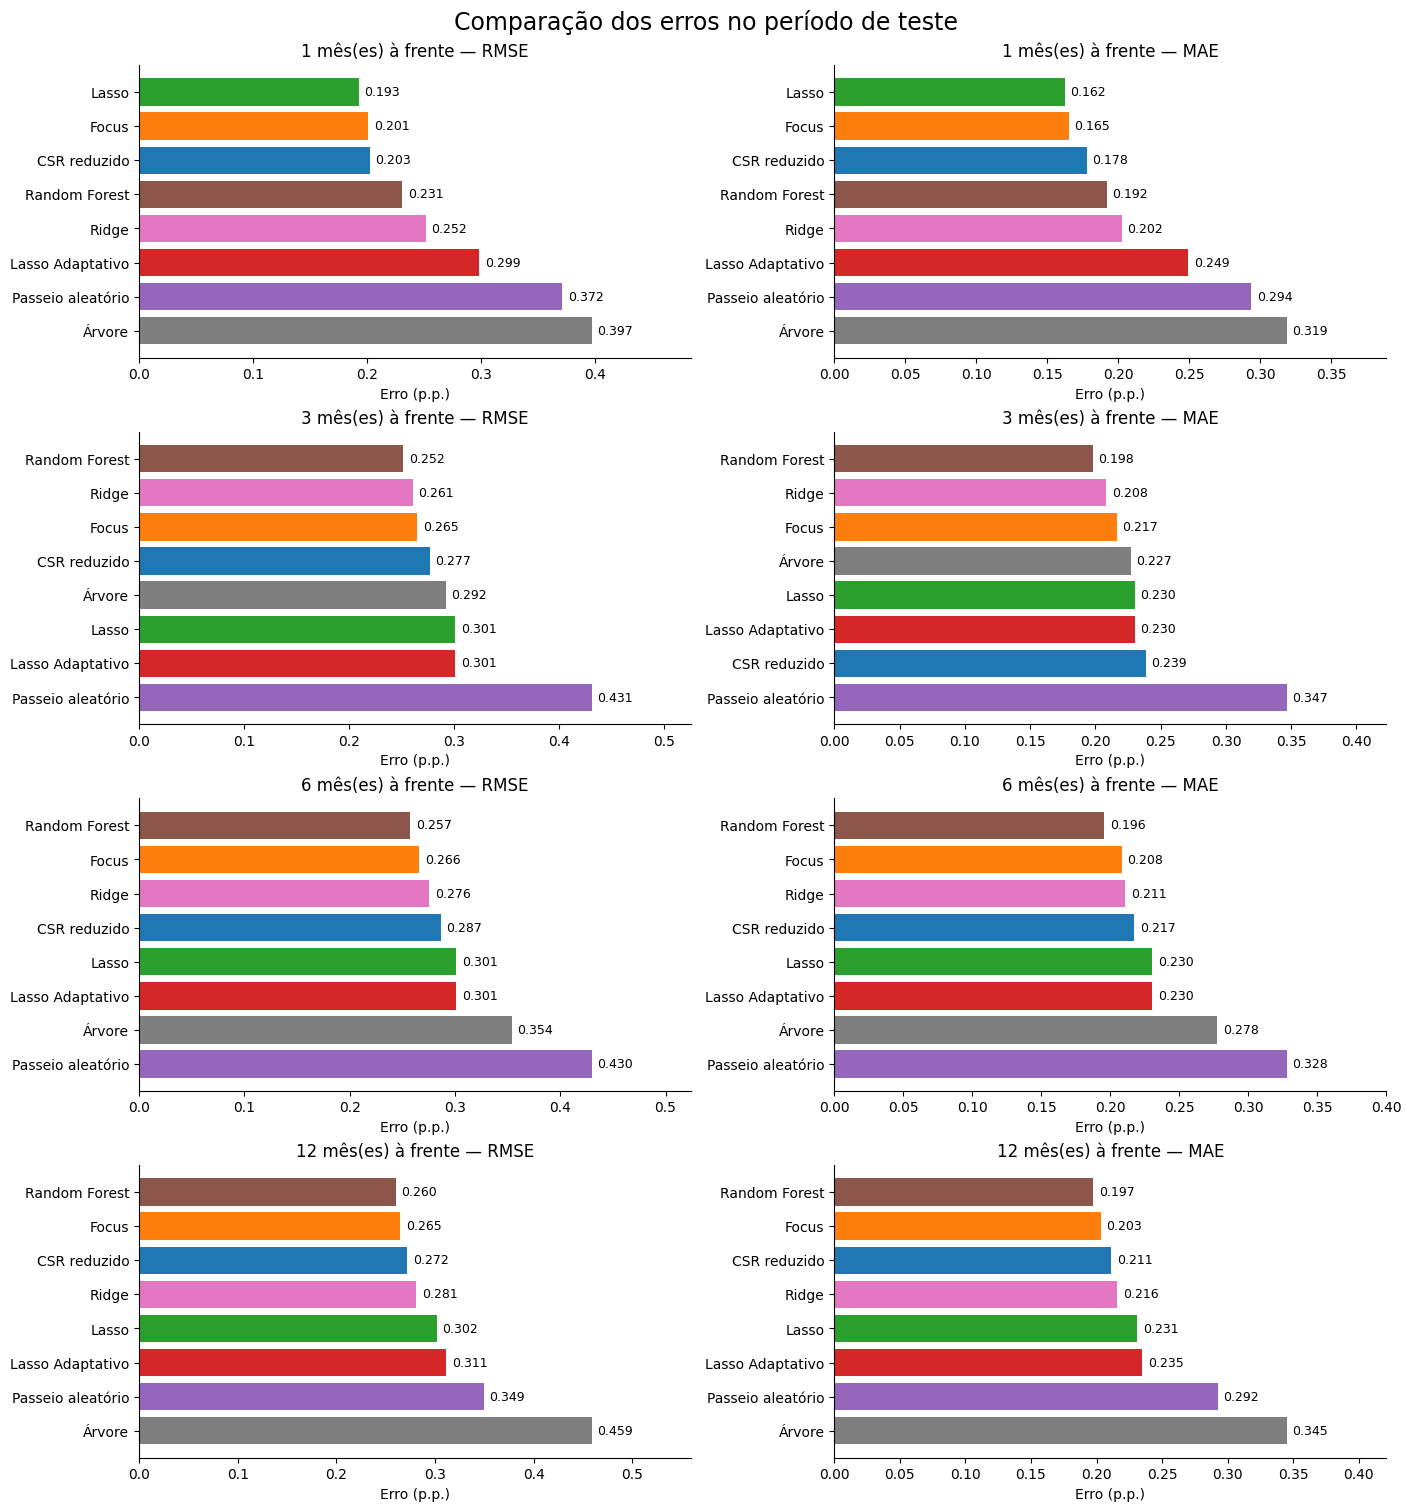

In [30]:
fig, eixos = plt.subplots(len(horizontes), 2, figsize=(14, 15), constrained_layout=True)
for linha, h in enumerate(horizontes):
    for coluna, metrica in enumerate(['RMSE', 'MAE']):
        dados = metricas[metricas['h'] == h].sort_values(metrica)
        ax = eixos[linha, coluna]
        barras = ax.barh(dados['modelo'], dados[metrica], color=[cores[m] for m in dados['modelo']])
        ax.bar_label(barras, fmt='%.3f', padding=4, fontsize=9)
        ax.invert_yaxis()
        ax.set_xlim(0, dados[metrica].max() * 1.22)
        ax.set_title(f'{h} mês(es) à frente — {metrica}')
        ax.set_xlabel('Erro (p.p.)')
fig.suptitle('Comparação dos erros no período de teste', fontsize=17)
fig.savefig(pasta_graficos / '01_comparacao_erros.png', dpi=150)
plt.show()


### 9.2. Previsto versus observado

Cada painel compara um modelo com o IPCA observado, sempre no mês previsto. Altere `h_visualizar` para 1, 3, 6 ou 12 e execute novamente. A mesma escala facilita comparar os painéis.

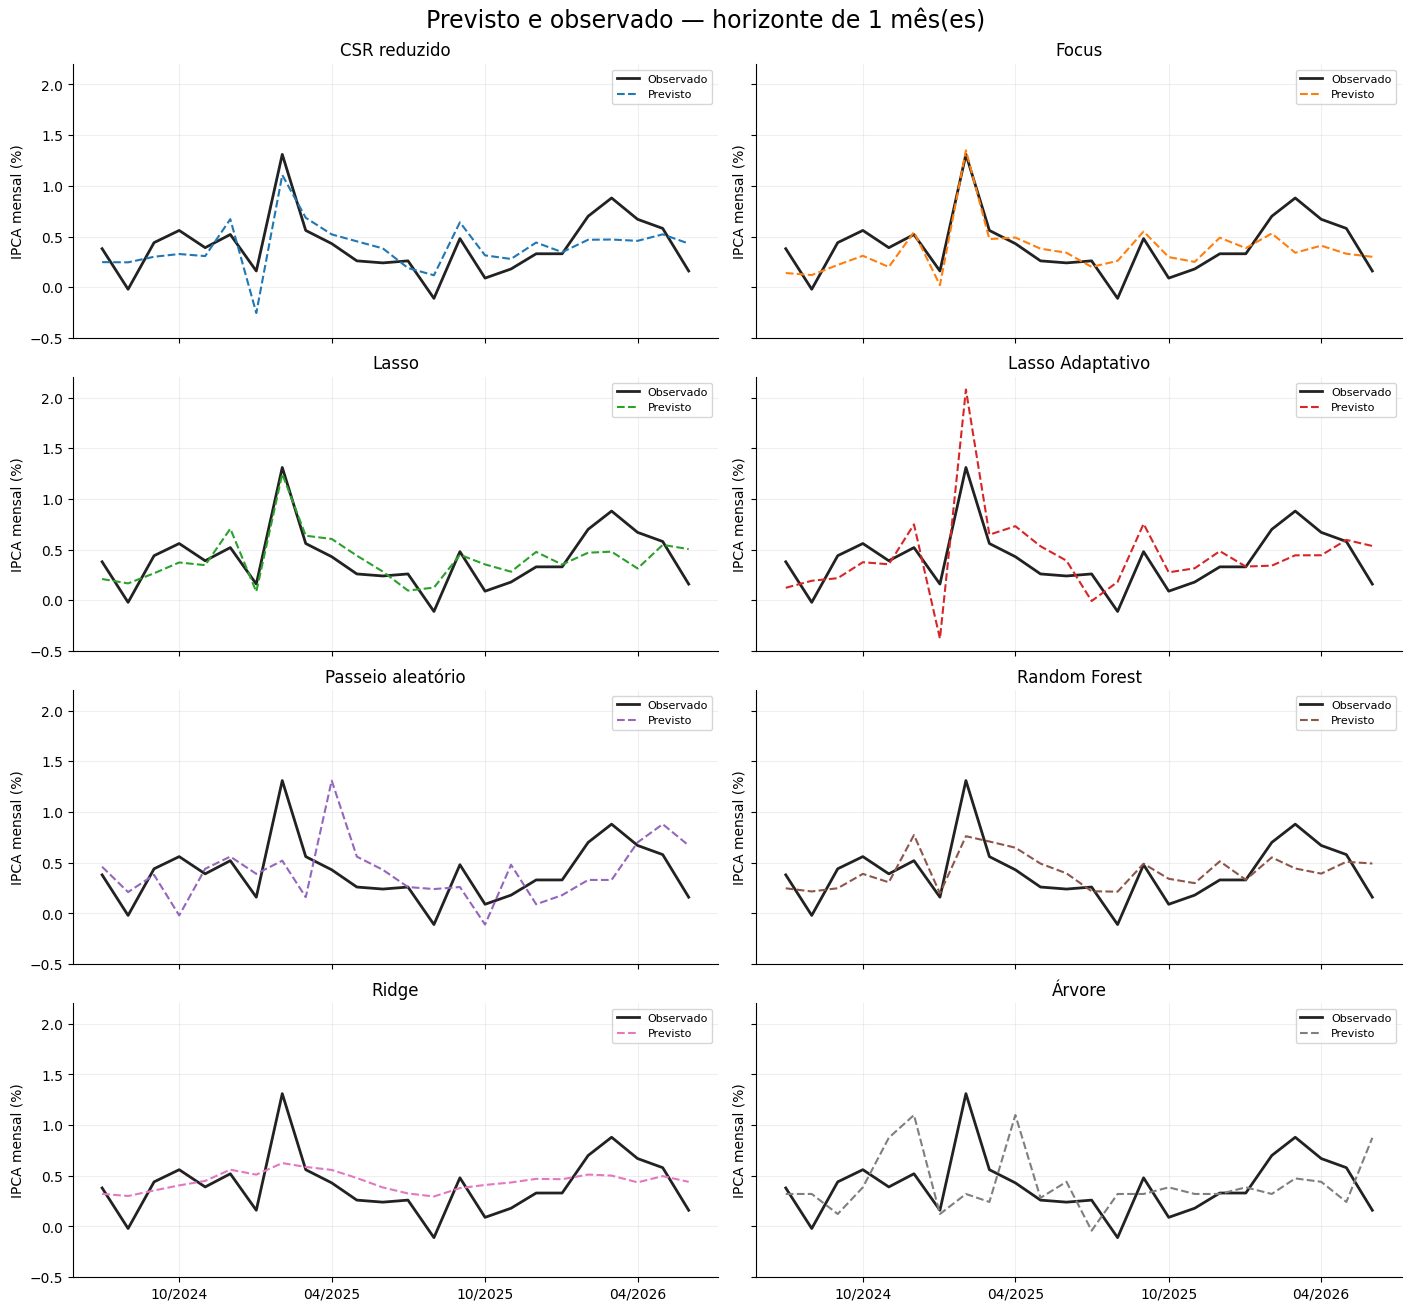

In [34]:
h_visualizar = 1
dados_h = previsoes[previsoes['h'] == h_visualizar]
nomes = sorted(dados_h['modelo'].unique())
fig, eixos = plt.subplots(4, 2, figsize=(14, 13), sharex=True, sharey=True, constrained_layout=True)
for ax, nome in zip(eixos.flat, nomes):
    dados = dados_h[dados_h['modelo'] == nome].sort_values('data_alvo')
    ax.plot(dados['data_alvo'], dados['observado'], color='#222222', label='Observado', linewidth=2)
    ax.plot(dados['data_alvo'], dados['previsto'], color=cores[nome], label='Previsto', linestyle='--')
    ax.set_title(nome)
    ax.set_ylabel('IPCA mensal (%)')
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
fig.suptitle(f'Previsto e observado — horizonte de {h_visualizar} mês(es)', fontsize=17)
fig.savefig(pasta_graficos / f'02_previsto_observado_h{h_visualizar}.png', dpi=150)
plt.show()


### 9.3. Modelo selecionado na validação versus Focus

Mostramos os quatro horizontes. O nome em cada painel vem da validação, não do menor erro encontrado depois de olhar o teste.

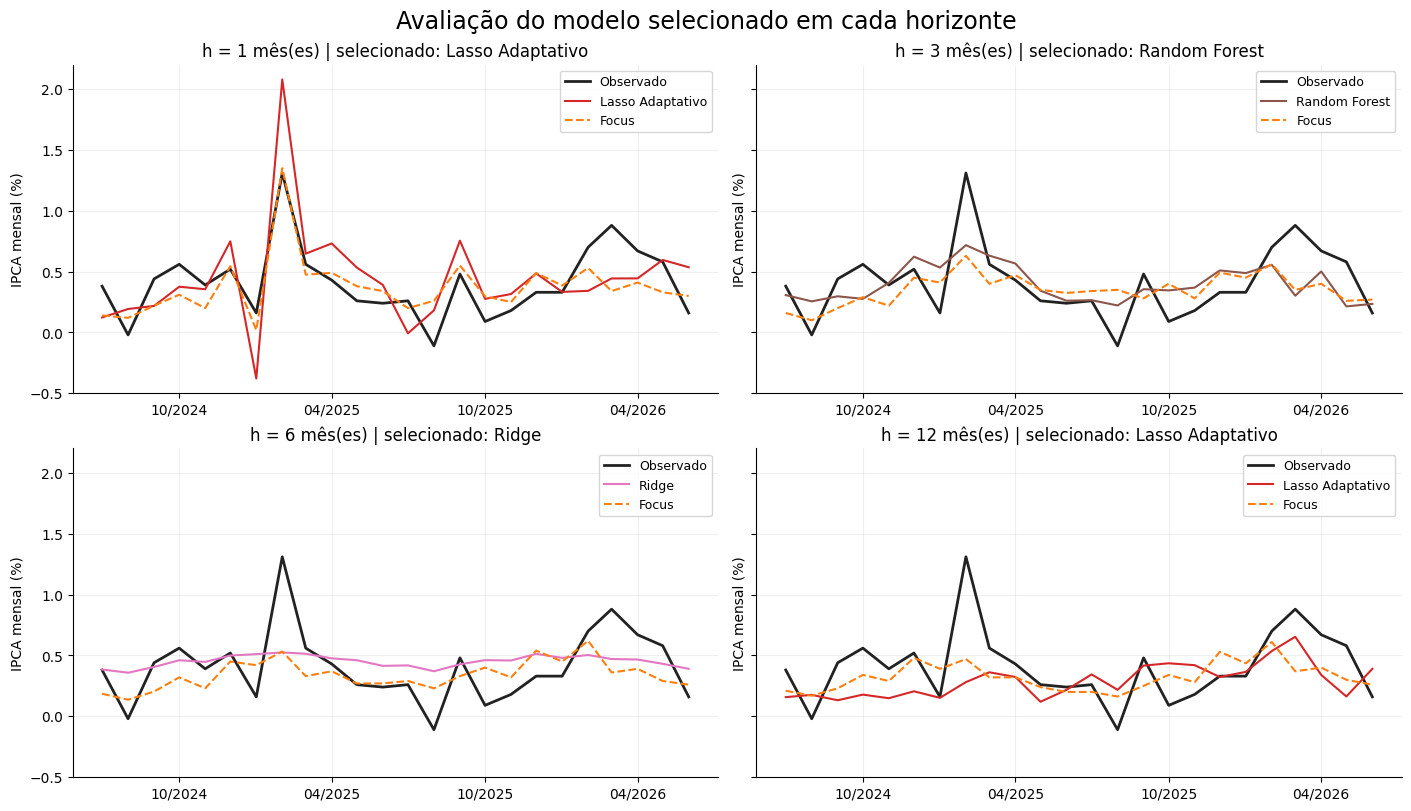

In [35]:
fig, eixos = plt.subplots(2, 2, figsize=(14, 8), sharey=True, constrained_layout=True)
for ax, h in zip(eixos.flat, horizontes):
    nome = selecionados.loc[selecionados['h'] == h, 'modelo'].iloc[0]
    dados = previsoes[(previsoes['h'] == h) & (previsoes['modelo'] == nome)].sort_values('data_alvo')
    focus = previsoes[(previsoes['h'] == h) & (previsoes['modelo'] == 'Focus')].sort_values('data_alvo')
    ax.plot(dados['data_alvo'], dados['observado'], color='#222222', label='Observado', linewidth=2)
    ax.plot(dados['data_alvo'], dados['previsto'], color=cores[nome], label=nome)
    ax.plot(focus['data_alvo'], focus['previsto'], color=cores['Focus'], label='Focus', linestyle='--')
    ax.set_title(f'h = {h} mês(es) | selecionado: {nome}')
    ax.set_ylabel('IPCA mensal (%)')
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
    ax.grid(alpha=.2)
    ax.legend(fontsize=9)
fig.suptitle('Avaliação do modelo selecionado em cada horizonte', fontsize=17)
fig.savefig(pasta_graficos / '03_selecionados_focus.png', dpi=150)
plt.show()


### 9.4. Em quais meses o modelo errou mais?

Erro = previsto − observado. Acima de zero indica superestimação; abaixo, subestimação. Altere `modelo_visualizar` e `h_visualizar` para examinar outra combinação.

In [26]:
modelos_finais.keys()

dict_keys([(1, 'Ridge'), (1, 'Lasso'), (1, 'Lasso Adaptativo'), (1, 'Árvore'), (1, 'Random Forest'), (1, 'CSR reduzido'), (3, 'Ridge'), (3, 'Lasso'), (3, 'Lasso Adaptativo'), (3, 'Árvore'), (3, 'Random Forest'), (3, 'CSR reduzido'), (6, 'Ridge'), (6, 'Lasso'), (6, 'Lasso Adaptativo'), (6, 'Árvore'), (6, 'Random Forest'), (6, 'CSR reduzido'), (12, 'Ridge'), (12, 'Lasso'), (12, 'Lasso Adaptativo'), (12, 'Árvore'), (12, 'Random Forest'), (12, 'CSR reduzido')])

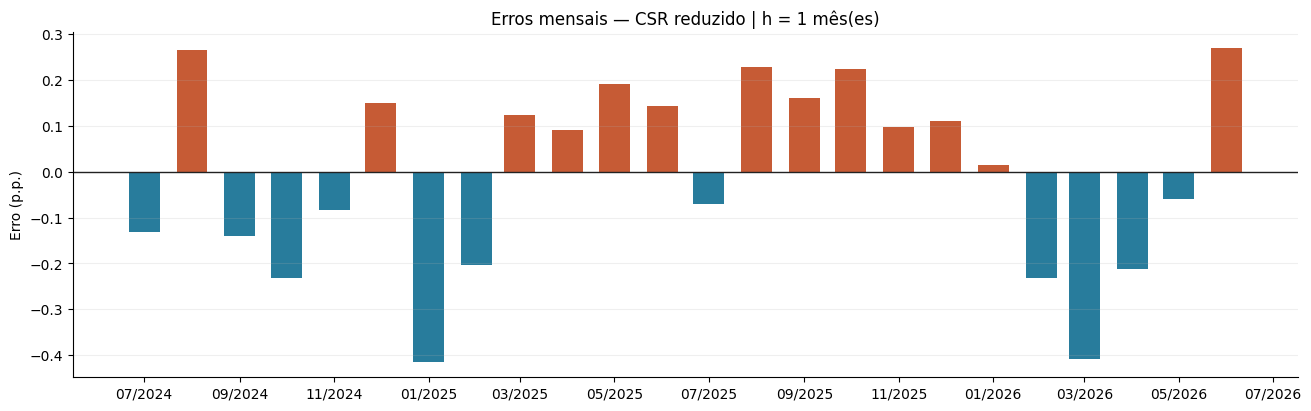

In [36]:
modelo_visualizar = 'CSR reduzido'
h_visualizar = 1
dados = previsoes[(previsoes['h'] == h_visualizar) & (previsoes['modelo'] == modelo_visualizar)].sort_values('data_alvo')
fig, ax = plt.subplots(figsize=(13, 4), constrained_layout=True)
ax.bar(dados['data_alvo'], dados['erro'], width=20,
       color=np.where(dados['erro'] >= 0, '#c65b35', '#287c9c'))
ax.axhline(0, color='#222222', linewidth=1)
ax.set_title(f'Erros mensais — {modelo_visualizar} | h = {h_visualizar} mês(es)')
ax.set_ylabel('Erro (p.p.)')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
ax.grid(axis='y', alpha=.2)
fig.savefig(pasta_graficos / f'04_erros_mensais_h{h_visualizar}.png', dpi=150)
plt.show()


## Experimento: reestimação mensal dos modelos

Mantemos os hiperparâmetros selecionados antes do teste e ampliamos o treino a cada mês. O objetivo é isolar o efeito da atualização, sem misturá-lo com novas variáveis, novas buscas ou outros modelos.

Execute as células de configuração, tratamento e definição dos modelos da etapa 8 antes desta célula. Não é necessário repetir a coleta nem a busca completa. Os dados e os benchmarks são os mesmos da execução de referência.

**Limitação:** este é um experimento retrospectivo em um teste já examinado, não uma nova confirmação independente. Os atrasos de publicação das explicativas ainda precisam ser modelados. Novas buscas, conjuntos de variáveis e correção do Focus ficam para experimentos separados, com seleção em validação temporal. A Dash mantém os resultados anteriores.

h=1: origem 06/2024, 252 observações no treino
h=1: origem 07/2024, 253 observações no treino
h=1: origem 08/2024, 254 observações no treino
h=1: origem 09/2024, 255 observações no treino
h=1: origem 10/2024, 256 observações no treino
h=1: origem 11/2024, 257 observações no treino
h=1: origem 12/2024, 258 observações no treino
h=1: origem 01/2025, 259 observações no treino
h=1: origem 02/2025, 260 observações no treino
h=1: origem 03/2025, 261 observações no treino
h=1: origem 04/2025, 262 observações no treino
h=1: origem 05/2025, 263 observações no treino
h=1: origem 06/2025, 264 observações no treino
h=1: origem 07/2025, 265 observações no treino
h=1: origem 08/2025, 266 observações no treino
h=1: origem 09/2025, 267 observações no treino
h=1: origem 10/2025, 268 observações no treino
h=1: origem 11/2025, 269 observações no treino
h=1: origem 12/2025, 270 observações no treino
h=1: origem 01/2026, 271 observações no treino
h=1: origem 02/2026, 272 observações no treino
h=1: origem 0

,h,modelo,RMSE_fixo,RMSE_mensal,variacao_RMSE_pct
0,1,CSR reduzido,0.2025,0.2025,-0.0115
1,1,Focus,0.2013,0.2013,0.0000
2,1,Lasso,0.1927,0.1934,0.3553
3,1,Lasso Adaptativo,0.2988,0.2842,-4.8833
4,1,Passeio aleatório,0.3715,0.3715,0.0000
5,1,Random Forest,0.2312,0.2276,-1.5661
6,1,Ridge,0.2520,0.2525,0.2163
7,1,Árvore,0.3974,0.2994,-24.6427
8,3,CSR reduzido,0.2771,0.2845,2.6880
9,3,Focus,0.2651,0.2651,0.0000


Experimento salvo em: c:\Users\Usuário\Desktop\projeto_ml\ipca_lab\resultados\experimentos\20261003_144148_mensal


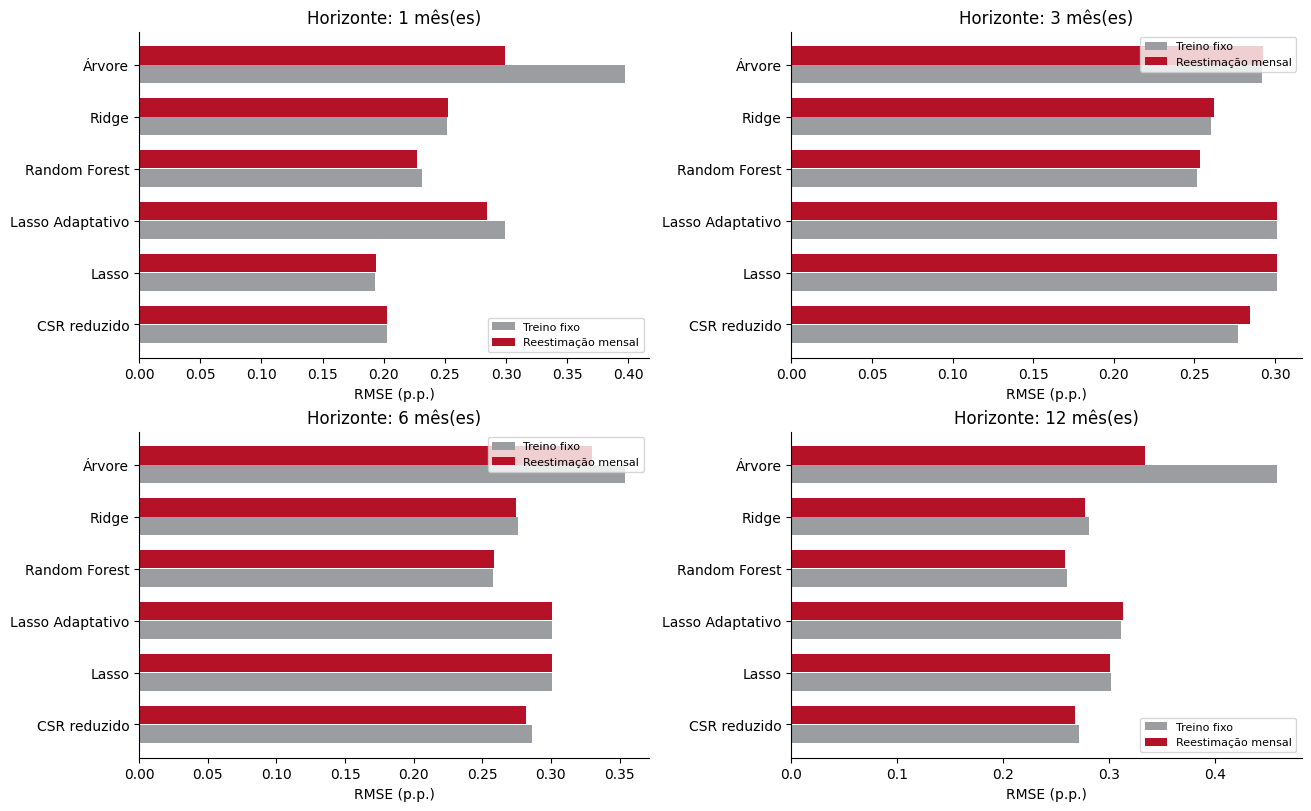

In [33]:
# ========= Reestimação mensal: janela expansiva ========= #
# Execute antes as células de pacotes, tratamento e definição dos modelos (8.1–8.4).
# Os hiperparâmetros permanecem congelados na seleção anterior ao teste.
from datetime import datetime
from zoneinfo import ZoneInfo

PASTA_REFERENCIA = RAIZ / 'resultados' / '20261003_141519_estacionariedade'
configuracoes = pd.read_csv(PASTA_REFERENCIA / 'validacao_modelos.csv')
previsoes_fixas = pd.read_csv(PASTA_REFERENCIA / 'previsoes_teste.csv',
                            parse_dates=['data_origem', 'data_alvo'])
manifesto_referencia = json.loads((PASTA_REFERENCIA / 'manifesto.json').read_text(encoding='utf-8'))
assert hashlib.sha256(ARQUIVO_BASE.read_bytes()).hexdigest() == manifesto_referencia['sha256_base']

linhas_mensais, auditoria_mensal, ajustes_mensais = [], [], []
for h in HORIZONTES:
    alvos = df_ipca['date'] + pd.DateOffset(months=h)
    origens = df_ipca.index[alvos.isin(DATAS_TESTE)]
    for indice in origens:
        origem = df_ipca.loc[indice, 'date']
        # Conservador: o alvo de treino deve ser de mês anterior à origem.
        # Isso não substitui a modelagem dos calendários de publicação das explicativas.
        indices_treino = df_ipca.index[(alvos < origem) & (df_ipca.index >= 4)]
        tr, te, cols, rel, _, _ = dividir_com_tratamento(indices_treino, [indice], h)
        assert tr.data_alvo.max() < origem
        auditoria_mensal.append({'h': h, 'data_origem': origem,
            'ultimo_alvo_treino': tr.data_alvo.max(), 'n_treino': len(tr),
            'n_features': len(cols), 'fim_testes_estacionariedade': df_ipca.loc[max(indices_treino), 'date']})
        for nome, (construtor, _) in modelos.items():
            linha = configuracoes.loc[configuracoes.h.eq(h) & configuracoes.modelo.eq(nome)]
            assert len(linha) == 1
            parametros = json.loads(linha.iloc[0].parametros)
            ajuste = ajustar_modelo(construtor, parametros, tr[cols], tr['alvo'])
            if not ajuste.convergiu_:
                raise ValueError(f'Sem convergência: {nome}, h={h}, origem={origem}. Nenhum candidato substituído pelo resultado no teste.')
            previsto = float(ajuste.predict(te[cols])[0])
            linhas_mensais.append({'h': h, 'modelo': nome, 'data_origem': origem,
                'data_alvo': te.data_alvo.iloc[0], 'observado': float(te.alvo.iloc[0]),
                'previsto': previsto})
            ajustes_mensais.append({'h': h, 'modelo': nome, 'data_origem': origem,
                'parametros': json.dumps(parametros), 'convergiu': True})
        print(f'h={h}: origem {origem:%m/%Y}, {len(tr)} observações no treino', flush=True)

# ========= Comparação na mesma amostra ========= #
# Benchmarks inalterados: a reestimação só se aplica aos seis modelos treinados.
benchmarks = previsoes_fixas.loc[previsoes_fixas.modelo.isin(['Focus', 'Passeio aleatório'])]
previsoes_mensais = pd.concat([pd.DataFrame(linhas_mensais), benchmarks], ignore_index=True)
assert len(previsoes_mensais) == len(previsoes_fixas) == 768
assert not previsoes_mensais.duplicated(['h', 'modelo', 'data_alvo']).any()
assert np.isfinite(previsoes_mensais[['previsto', 'observado']]).all().all()
chaves = ['h', 'modelo', 'data_origem', 'data_alvo']
comparar_alvos = previsoes_mensais.merge(previsoes_fixas, on=chaves, validate='one_to_one')
np.testing.assert_allclose(comparar_alvos.observado_x, comparar_alvos.observado_y)

metricas_mensais = previsoes_mensais.groupby(['h', 'modelo']).apply(
    lambda g: pd.Series({'RMSE': mean_squared_error(g.observado, g.previsto) ** .5,
                        'MAE': mean_absolute_error(g.observado, g.previsto), 'n': len(g)}),
    include_groups=False).reset_index()
metricas_fixas = pd.read_csv(PASTA_REFERENCIA / 'metricas.csv')
comparacao_mensal = metricas_fixas.merge(metricas_mensais, on=['h', 'modelo'],
                                       suffixes=('_fixo', '_mensal'), validate='one_to_one')
comparacao_mensal['variacao_RMSE_pct'] = 100 * (comparacao_mensal.RMSE_mensal / comparacao_mensal.RMSE_fixo - 1)
print('Variação negativa indica redução do RMSE. Comparação exploratória, não seleção de vencedor.')
display(comparacao_mensal[['h', 'modelo', 'RMSE_fixo', 'RMSE_mensal', 'variacao_RMSE_pct']].round(4))

# ========= Salvar experimento sem substituir a Dash ========= #
destino_mensal = RAIZ / 'resultados' / 'experimentos' / (datetime.now(ZoneInfo('America/Sao_Paulo')).strftime('%Y%m%d_%H%M%S') + '_mensal')
destino_mensal.mkdir(parents=True, exist_ok=False)
previsoes_mensais.to_csv(destino_mensal / 'previsoes_mensais.csv', index=False)
metricas_mensais.to_csv(destino_mensal / 'metricas_mensais.csv', index=False)
comparacao_mensal.to_csv(destino_mensal / 'comparacao_rmse.csv', index=False)
pd.DataFrame(auditoria_mensal).to_csv(destino_mensal / 'auditoria_mensal.csv', index=False)
pd.DataFrame(ajustes_mensais).to_csv(destino_mensal / 'parametros_por_origem.csv', index=False)
(destino_mensal / 'manifesto.json').write_text(json.dumps({
    'referencia': str(PASTA_REFERENCIA.relative_to(RAIZ)),
    'base_sha256': manifesto_referencia['sha256_base'],
    'metodo': 'janela expansiva; reestimação mensal; parâmetros congelados antes do teste',
    'limitacoes': 'Dados revisados; atrasos de publicação não integralmente modelados; teste já examinado, comparação exploratória. Nenhuma promoção automática.',
}, ensure_ascii=False, indent=2), encoding='utf-8')
print('Experimento salvo em:', destino_mensal)

# ========= Visualização do efeito da reestimação ========= #
import matplotlib.pyplot as plt
fig, eixos = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for ax, h in zip(eixos.flat, HORIZONTES):
    dados = comparacao_mensal.loc[comparacao_mensal.h.eq(h) & comparacao_mensal.modelo.isin(modelos)]
    pos = np.arange(len(dados))
    ax.barh(pos - .18, dados.RMSE_fixo, height=.35, color='#9b9da1', label='Treino fixo')
    ax.barh(pos + .18, dados.RMSE_mensal, height=.35, color='#b51227', label='Reestimação mensal')
    ax.set_yticks(pos, dados.modelo)
    ax.set_title(f'Horizonte: {h} mês(es)')
    ax.set_xlabel('RMSE (p.p.)')
    ax.legend(fontsize=8)
fig.savefig(destino_mensal / 'comparacao_rmse.png', dpi=130)
plt.show()


## 11. Experimento: conjuntos menores de variáveis

**Resultados da execução de 05/10/2026, recuperados dos arquivos salvos.** As tabelas e o gráfico abaixo já podem ser consultados, sem executar novamente.

Comparamos **Enxuto (16 variáveis)**, **Macroeconomico (35)** e **Completo (106)**. A escolha de cada conjunto usa 12 origens de validação anteriores ao teste por horizonte, com reestimação mensal. Mantivemos os hiperparâmetros pré-selecionados e os lags atuais de 1 e 4 meses. Todos os conjuntos usam as mesmas datas.

No teste exploratório, 6 combinações melhoraram, 4 pioraram e 14 ficaram equivalentes à base completa reestimada mensalmente. Como os hiperparâmetros já foram ajustados no pré-teste e o teste histórico já foi examinado, esta comparação não representa uma nova avaliação independente. Dados revisados e calendários de divulgação incompletos continuam sendo limitações.

Para **refazer** o experimento, execute antes as células da etapa 8 de pacotes/configuração, testes de estacionariedade, tratamento e definição dos modelos. Depois execute as três células desta seção em ordem. Os resultados exibidos foram restaurados do disco, por isso as células estão sem contador de execução nesta sessão.

Arquivos: `resultados/experimentos/20261005_154421_variaveis`.


In [ ]:
# ========= Experimento: conjuntos de variáveis ========= #
from datetime import datetime
from zoneinfo import ZoneInfo

REFERENCIA_VARIAVEIS = RAIZ / 'resultados' / '20261003_141519_estacionariedade'
REFERENCIA_MENSAL = RAIZ / 'resultados/experimentos/20261003_144148_mensal'
parametros_variaveis = pd.read_csv(REFERENCIA_VARIAVEIS / 'validacao_modelos.csv')
manifesto_base = json.loads((REFERENCIA_VARIAVEIS / 'manifesto.json').read_text(encoding='utf-8'))
assert hashlib.sha256(ARQUIVO_BASE.read_bytes()).hexdigest() == manifesto_base['sha256_base']
MESES_VALIDACAO = 12
CONJUNTOS = ['Enxuto', 'Macroeconomico', 'Completo']

def colunas_do_conjunto(colunas, conjunto, h):
    # Focus do mesmo horizonte, lags do IPCA e sazonalidade.
    enxuto = [c for c in colunas if c.startswith(('ipca_lag', 'mes_'))
              or c == f'expectativa_ipca_h_{h}'
              or c.startswith(f'expectativa_ipca_h_{h}_lag')]
    macro = ['ipca_15', 'cambio', 'pib_mensal', 'selic', 'igp_m',
             'pim_pf', 'volume', 'desemprego', 'brent_fob']
    if conjunto == 'Enxuto':
        return enxuto
    if conjunto == 'Macroeconomico':
        return [c for c in colunas if c in enxuto or c in macro
                or any(c.startswith(v + '_lag') for v in macro)]
    if conjunto == 'Completo':
        return list(colunas)
    raise ValueError(conjunto)

def parametros_congelados(h, nome):
    linha = parametros_variaveis.loc[parametros_variaveis.h.eq(h) & parametros_variaveis.modelo.eq(nome)]
    assert len(linha) == 1
    return json.loads(linha.iloc[0].parametros)

print('Hiperparâmetros da referência, lags atuais e datas preservados para isolar o conjunto de variáveis.')
print('Validação: últimas 12 origens com alvo conhecido antes da primeira origem do teste, por horizonte.')



h,conjunto,n_variaveis
1,Enxuto,16
1,Macroeconomico,35
1,Completo,106
3,Enxuto,16
3,Macroeconomico,35
3,Completo,106
6,Enxuto,16
6,Macroeconomico,35
6,Completo,106
12,Enxuto,16


In [ ]:
# ========= Selecionar variáveis pela validação mensal ========= #
previsoes_validacao_variaveis, auditoria_variaveis, lista_colunas = [], [], []
for h in HORIZONTES:
    alvos = df_ipca.date + pd.DateOffset(months=h)
    primeira_origem_teste = DATAS_TESTE.min() - pd.DateOffset(months=h)
    origens_validacao = df_ipca.index[(alvos < primeira_origem_teste) & (df_ipca.index >= 4)][-MESES_VALIDACAO:]
    assert len(origens_validacao) == MESES_VALIDACAO
    for indice in origens_validacao:
        origem = df_ipca.loc[indice, 'date']
        indices_treino = df_ipca.index[(alvos < origem) & (df_ipca.index >= 4)]
        tr, va, todas, _, _, _ = dividir_com_tratamento(indices_treino, [indice], h)
        assert tr.data_alvo.max() < origem
        assert va.data_alvo.iloc[0] < primeira_origem_teste
        auditoria_variaveis.append({'fase': 'validacao', 'h': h, 'origem': origem,
            'ultimo_alvo_treino': tr.data_alvo.max(), 'data_alvo': va.data_alvo.iloc[0],
            'primeira_origem_teste': primeira_origem_teste, 'n_treino': len(tr)})
        for conjunto in CONJUNTOS:
            cols = colunas_do_conjunto(todas, conjunto, h)
            if indice == origens_validacao[0]:
                lista_colunas.append({'h': h, 'conjunto': conjunto, 'n_variaveis': len(cols), 'colunas': json.dumps(cols)})
            for nome, (construtor, _) in modelos.items():
                ajuste = ajustar_modelo(construtor, parametros_congelados(h, nome), tr[cols], tr.alvo)
                valor = float(ajuste.predict(va[cols])[0]) if ajuste.convergiu_ else np.nan
                previsoes_validacao_variaveis.append({'h': h, 'modelo': nome, 'conjunto': conjunto,
                    'data_origem': origem, 'data_alvo': va.data_alvo.iloc[0],
                    'observado': float(va.alvo.iloc[0]), 'previsto': valor, 'convergiu': ajuste.convergiu_})
        print(f'Validação h={h}, origem {origem:%m/%Y}: três conjuntos avaliados.', flush=True)

validacao_variaveis = pd.DataFrame(previsoes_validacao_variaveis)
scores_variaveis = validacao_variaveis.groupby(['h', 'modelo', 'conjunto']).apply(
    lambda g: pd.Series({'RMSE_validacao': np.sqrt(np.mean((g.observado - g.previsto) ** 2))
        if g.convergiu.all() and len(g) == MESES_VALIDACAO else np.inf,
        'n_validacao': len(g), 'falhas_convergencia': int((~g.convergiu).sum())}),
    include_groups=False).reset_index()
colunas_variaveis = pd.DataFrame(lista_colunas)
scores_variaveis = scores_variaveis.merge(colunas_variaveis[['h', 'conjunto', 'n_variaveis']], on=['h', 'conjunto'])
escolhas_variaveis = scores_variaveis.sort_values(['h', 'modelo', 'RMSE_validacao', 'n_variaveis', 'conjunto']).groupby(['h', 'modelo']).head(1).reset_index(drop=True)
assert len(escolhas_variaveis) == 24 and np.isfinite(escolhas_variaveis.RMSE_validacao).all()
display(escolhas_variaveis.round(4))

# Salva a decisão antes de consultar resultados no teste.
pasta_variaveis = RAIZ / 'resultados/experimentos' / (datetime.now(ZoneInfo('America/Sao_Paulo')).strftime('%Y%m%d_%H%M%S') + '_variaveis')
pasta_variaveis.mkdir(parents=True, exist_ok=False)
escolhas_variaveis.to_csv(pasta_variaveis / 'escolhas_validacao.csv', index=False)
scores_variaveis.to_csv(pasta_variaveis / 'scores_validacao.csv', index=False)
validacao_variaveis.to_csv(pasta_variaveis / 'previsoes_validacao.csv', index=False)
colunas_variaveis.to_csv(pasta_variaveis / 'conjuntos_variaveis.csv', index=False)



h,modelo,conjunto,RMSE_validacao,n_validacao,falhas_convergencia,n_variaveis
1,CSR reduzido,Enxuto,0.2312,12.0,0.0,16
1,Lasso,Completo,0.1991,12.0,0.0,106
1,Lasso Adaptativo,Macroeconomico,0.2176,12.0,0.0,35
1,Random Forest,Macroeconomico,0.2203,12.0,0.0,35
1,Ridge,Completo,0.2121,12.0,0.0,106
1,Árvore,Macroeconomico,0.2273,12.0,0.0,35
3,CSR reduzido,Enxuto,0.2332,12.0,0.0,16
3,Lasso,Enxuto,0.2786,12.0,0.0,16
3,Lasso Adaptativo,Enxuto,0.2600,12.0,0.0,16
3,Random Forest,Completo,0.1961,12.0,0.0,106


h,modelo,conjunto,RMSE_completo,RMSE_novo,variacao_pct
1,CSR reduzido,Enxuto,0.2025,0.1942,-4.0922
1,Lasso,Completo,0.1934,0.1934,0.0000
1,Lasso Adaptativo,Macroeconomico,0.2842,0.1963,-30.9425
1,Random Forest,Macroeconomico,0.2276,0.2590,13.7878
1,Ridge,Completo,0.2525,0.2525,0.0000
1,Árvore,Macroeconomico,0.2994,0.2630,-12.1699
3,CSR reduzido,Enxuto,0.2845,0.2499,-12.1833
3,Lasso,Enxuto,0.3014,0.3014,0.0000
3,Lasso Adaptativo,Enxuto,0.3014,0.2806,-6.9126
3,Random Forest,Completo,0.2536,0.2536,0.0000


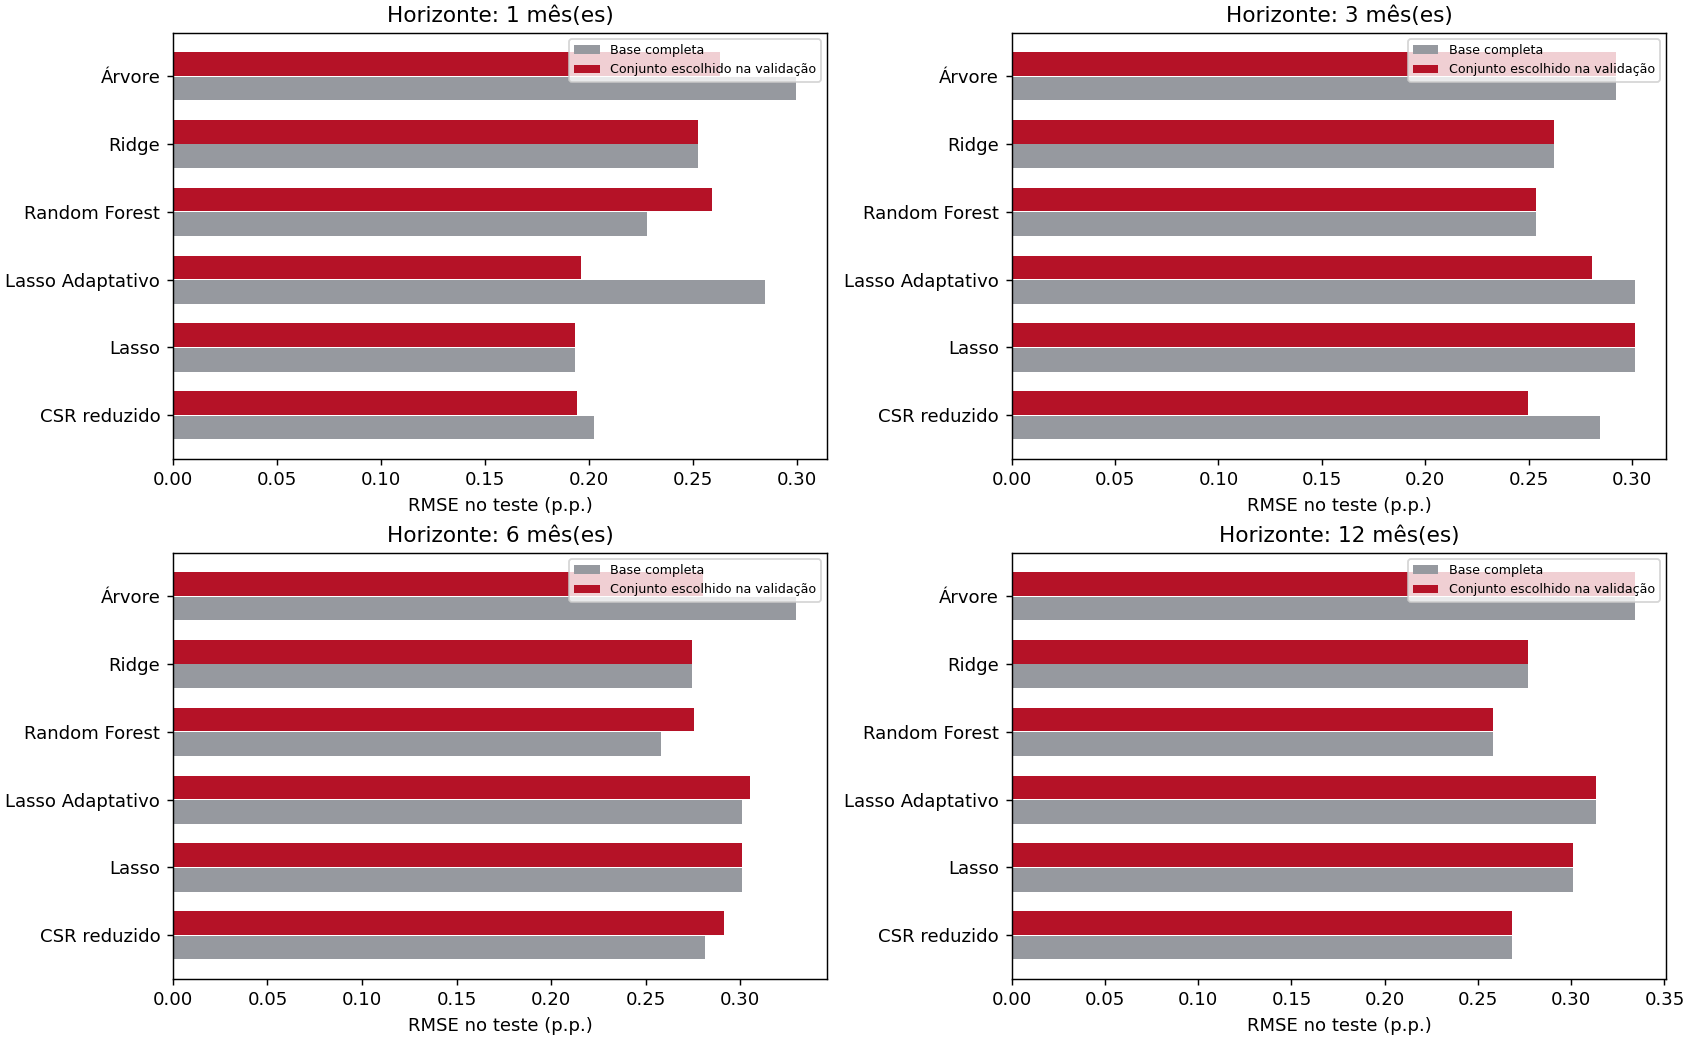

In [ ]:
# ========= Avaliar a escolha congelada no teste histórico ========= #
linhas_teste_variaveis = []
for h in HORIZONTES:
    alvos = df_ipca.date + pd.DateOffset(months=h)
    primeira_origem_teste = DATAS_TESTE.min() - pd.DateOffset(months=h)
    for indice in df_ipca.index[alvos.isin(DATAS_TESTE)]:
        origem = df_ipca.loc[indice, 'date']
        indices_treino = df_ipca.index[(alvos < origem) & (df_ipca.index >= 4)]
        tr, te, todas, _, _, _ = dividir_com_tratamento(indices_treino, [indice], h)
        auditoria_variaveis.append({'fase': 'teste', 'h': h, 'origem': origem,
            'ultimo_alvo_treino': tr.data_alvo.max(), 'data_alvo': te.data_alvo.iloc[0],
            'primeira_origem_teste': primeira_origem_teste, 'n_treino': len(tr)})
        for nome, (construtor, _) in modelos.items():
            escolha = escolhas_variaveis.loc[escolhas_variaveis.h.eq(h) & escolhas_variaveis.modelo.eq(nome)].iloc[0]
            cols = colunas_do_conjunto(todas, escolha.conjunto, h)
            ajuste = ajustar_modelo(construtor, parametros_congelados(h, nome), tr[cols], tr.alvo)
            if not ajuste.convergiu_:
                raise ValueError(f'Sem convergência no teste: {nome}, h={h}, {origem}. Investigar antes de concluir.')
            linhas_teste_variaveis.append({'h': h, 'modelo': nome, 'conjunto': escolha.conjunto,
                'data_origem': origem, 'data_alvo': te.data_alvo.iloc[0],
                'observado': float(te.alvo.iloc[0]), 'previsto': float(ajuste.predict(te[cols])[0])})
        print(f'Teste h={h}, origem {origem:%m/%Y}: seis modelos reajustados.', flush=True)

# ========= Comparar com a base completa, também reestimada mensalmente ========= #
previsoes_conjuntos = pd.DataFrame(linhas_teste_variaveis)
referencia_previsoes = pd.read_csv(REFERENCIA_MENSAL / 'previsoes_mensais.csv', parse_dates=['data_origem', 'data_alvo'])
chaves = ['h', 'modelo', 'data_origem', 'data_alvo']
alinhadas = previsoes_conjuntos.merge(referencia_previsoes, on=chaves, validate='one_to_one', suffixes=('_novo', '_anterior'))
assert len(alinhadas) == len(previsoes_conjuntos) == 576
np.testing.assert_allclose(alinhadas.observado_novo, alinhadas.observado_anterior)
completos = alinhadas.loc[alinhadas.conjunto.eq('Completo')]
np.testing.assert_allclose(completos.previsto_novo, completos.previsto_anterior, rtol=1e-7, atol=1e-9)
metricas_conjuntos = previsoes_conjuntos.groupby(['h', 'modelo', 'conjunto']).apply(
    lambda g: pd.Series({'RMSE_novo': np.sqrt(np.mean((g.observado - g.previsto) ** 2)),
                        'MAE_novo': np.mean(np.abs(g.observado - g.previsto)), 'n': len(g)}),
    include_groups=False).reset_index()
referencia_metricas = pd.read_csv(REFERENCIA_MENSAL / 'metricas_mensais.csv')
comparacao_variaveis = metricas_conjuntos.merge(referencia_metricas[['h', 'modelo', 'RMSE']].rename(columns={'RMSE': 'RMSE_completo'}), on=['h', 'modelo'], validate='one_to_one')
comparacao_variaveis['variacao_pct'] = 100 * (comparacao_variaveis.RMSE_novo / comparacao_variaveis.RMSE_completo - 1)
display(comparacao_variaveis[['h', 'modelo', 'conjunto', 'RMSE_completo', 'RMSE_novo', 'variacao_pct']].round(4))
previsoes_conjuntos.to_csv(pasta_variaveis / 'previsoes_teste.csv', index=False)
comparacao_variaveis.to_csv(pasta_variaveis / 'comparacao_rmse.csv', index=False)
pd.DataFrame(auditoria_variaveis).to_csv(pasta_variaveis / 'auditoria_temporal.csv', index=False)
parametros_variaveis.to_csv(pasta_variaveis / 'parametros_referencia.csv', index=False)

# ========= Gráfico do experimento ========= #
import matplotlib.pyplot as plt
fig, eixos = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for ax, h in zip(eixos.flat, HORIZONTES):
    dados = comparacao_variaveis.loc[comparacao_variaveis.h.eq(h)]
    pos = np.arange(len(dados))
    ax.barh(pos - .18, dados.RMSE_completo, height=.35, color='#96999f', label='Base completa')
    ax.barh(pos + .18, dados.RMSE_novo, height=.35, color='#b51227', label='Conjunto escolhido na validação')
    ax.set_yticks(pos, dados.modelo)
    ax.set_xlabel('RMSE no teste (p.p.)')
    ax.set_title(f'Horizonte: {h} mês(es)')
    ax.legend(fontsize=7)
fig.savefig(pasta_variaveis / 'comparacao_rmse.png', dpi=130)
plt.show()
(pasta_variaveis / 'manifesto.json').write_text(json.dumps({
    'status': 'completo', 'referencia_parametros': str(REFERENCIA_VARIAVEIS),
    'referencia_mensal': str(REFERENCIA_MENSAL), 'base_sha256': manifesto_base['sha256_base'],
    'validacao': '12 origens mensais anteriores ao teste por horizonte; seleção condicional aos hiperparâmetros previamente ajustados no pré-teste',
    'limitacoes': 'Teste já examinado, comparação exploratória. Dados revisados e calendário de divulgação incompleto. Nenhuma nova busca de hiperparâmetros, lags ou janela neste experimento.',
}, ensure_ascii=False, indent=2), encoding='utf-8')
print('Experimento concluído:', pasta_variaveis)
